## Evoluzione delle anime negli anni

Gli anime non sono solo titoli da guardare: sono un ecosistema fatto di produzione, generi, personaggi, voci, fan e comunità globali.

In questo notebook racconteremo come questo ecosistema prende forma nei dati: dalla crescita storica degli anime fino al modo in cui gli utenti li valutano, li amano e li organizzano nelle proprie liste.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
from solution.utils import utils


In [2]:
# load dataset
df_details = pd.read_csv("../../dataset/cleaned/details_cleaned.csv")
df_favs = pd.read_csv("../../dataset/cleaned/favs_cleaned.csv")
df_recommendations = pd.read_csv("../../dataset/cleaned/recommendations_cleaned.csv")
df_stats = pd.read_csv("../../dataset/cleaned/stats_cleaned.csv")
df_ratings = pd.read_csv("../../dataset/cleaned/ratings_cleaned.csv")
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")
df_characters_anime_works = pd.read_csv("../../dataset/cleaned/character_anime_works_cleaned.csv")
df_person_voice_works = pd.read_csv("../../dataset/cleaned/person_voice_works_cleaned.csv")
df_characters = pd.read_csv("../../dataset/cleaned/characters_cleaned.csv")
df_character_nicknames = pd.read_csv("../../dataset/cleaned/character_nicknames_cleaned.csv")

In [3]:
df_details['start_date'] = pd.to_datetime(df_details['start_date'], errors='coerce')
df_details['year'] = df_details['start_date'].dt.year.astype("Int64")
df_details['scored_by'] = pd.to_numeric(df_details['scored_by'], errors='coerce')
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")
df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")

## 1. LA CRESCITA STORICA DELLA PRODUZIONE ANIME

### 1.1 Come si è evoluta la produzione di anime nel tempo?

In [4]:
details = df_details.copy()
details = details.dropna(subset=['start_date'])

# Conteggio anime per anno
counts = (details['year'].value_counts().sort_index().reset_index())
counts.columns = ['year', 'anime_count']

fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

**La parabola della produzione: dal silenzio all'esplosione**

Per gran parte del Novecento, l'industria degli anime ha proceduto con un passo lento e constante. è stato un cammino silenzioso, fatto di sperimentazione e artigianalità, dove la produzione cresceva senza scosse evidenti. Ma è con l'arrivo degli anni '80 che qualcosa inizia a cambiare: il battito accelera, segnalando un interesse che travalica i confini nazionali.

**Il Nuovo Millennio e il picco storico**

Tuttavia, è dopo il 2000 che assistiamo a una vera e propria metamorfosi. La curva della produzione cambia ritmo in modo prepotente, spinta dalla digitalizzazione e da una domanda globale sempre più vorace. Questo crescendo culmina nel **2017**: l'anno d'oro, il vertice masssimo di un'espansione durata due decenni, in cui l'industria ha toccato il suo apice storico.

**Oltre la vetta: un nuovo equilibro**

Negli anni più recenti, i dati mostrano una lieva flessione. Non è però un segnale di crisi, ma il riflesso di un mercato che, dopo aver toccato vette incredibile nel 2017, cerca ora un nuovo equilibro. La tendenza generale rimane solida: il gigante è sveglio e continua a correre, consolidando la sua eredigtà come ecosistema culturale globale.
> **Nota sui dati:** 851 anime privi di data di inizio (2,9 % del dataset) sono stati esclusi da questo grafico. Il dataset contiene 157 titoli con anno 2026–2027 (annunciati ma non ancora usciti). Il grafico è volutamente limitato al 2024 per mostrare solo produzioni concluse.

### 1.2 L'albero genealogico degli anime: distribuzione dei generi

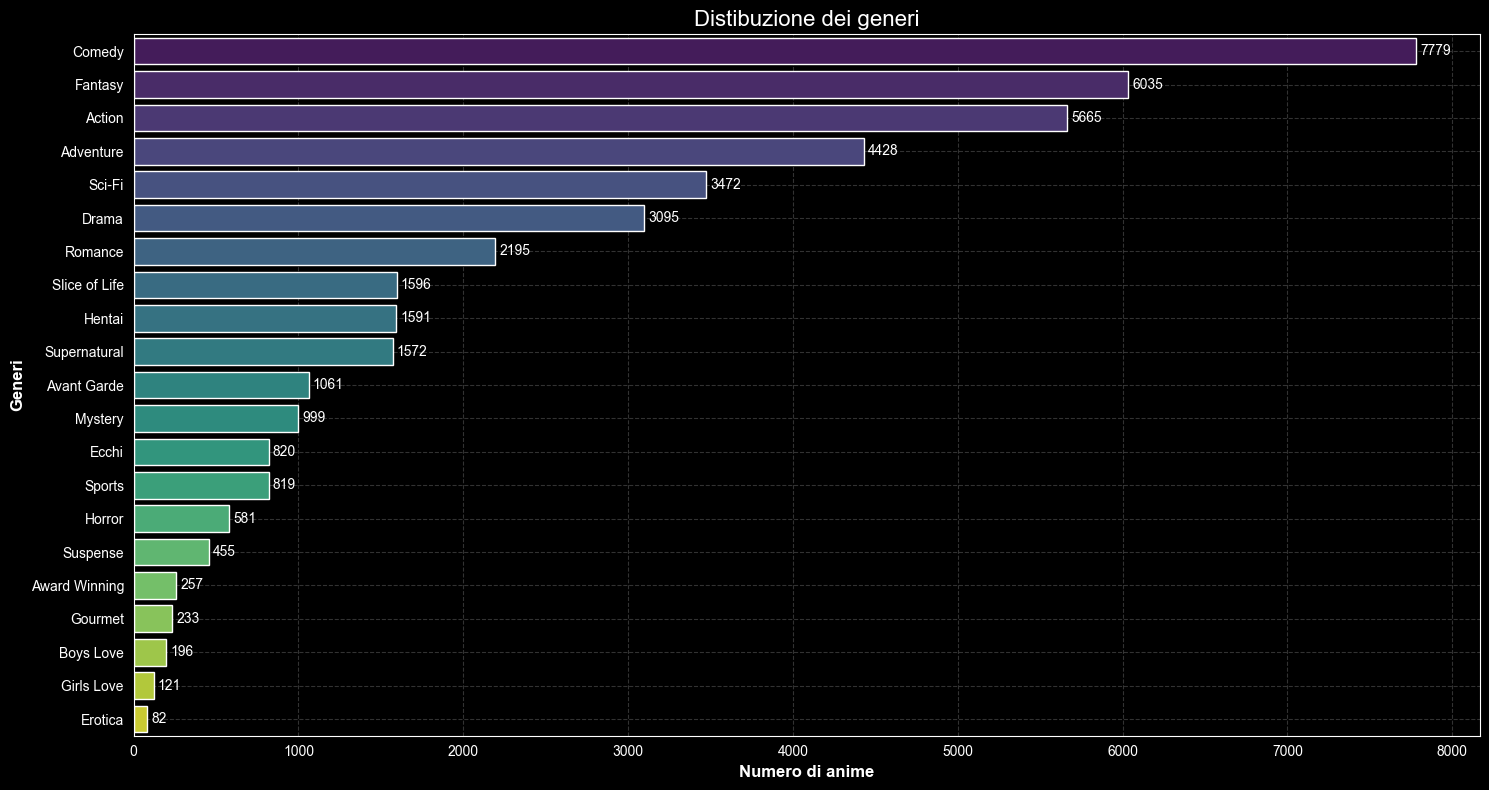

In [5]:
df_genres = df_details['genres'].copy()
df_genres = df_genres.apply(ast.literal_eval)

df_genres = df_genres.explode().dropna()
genre_count = df_genres.value_counts().reset_index()

genre_count.columns = ['genre', 'count']
# plot
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Distibuzione dei generi', fontsize=16)
plt.xlabel('Numero di anime', fontsize=12, fontweight='bold')
plt.ylabel('Generi', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()


**I giganti del settore: i pilastri del mercato**
Se osserviamo la foresta dei contenuti prodotti, i giganti che dominano la scena sono indubbiamente la **Commedia**, l'**Azione** e il **Fantasy**. Questi generi costituiscono le fondamenta dell'intera industria: la loro popolarità universale li rende i prodotti più "sicuri" e richiesti, capaci di attrarre un pubblico vastissimo che spazia dai giovanissimi ai fan storici.

**L'equilibrio tra evasione e introspezione**

Accanto ai leader indiscussi, notiamo una presenza solida di generi come **Adventure** e **Sci-Fi**, che alimentano l'immaginario fantastico tipico del medium. Tuttavia, l'analisi rivela che non c'è solo spettacolo: il successo di titoli **Drama** e **Slice of Life** dimostra un'industria profondamente radicata nell'esplorazione dei sentimenti umani e della vita quotidiana, capace di trasformare la normalità in narrazione epica.
> **Nota sui dati:** Il 20,7 % degli anime (5.983 titoli) non ha tag di genere nel dataset e non è incluso in questo grafico né in quello successivo. La distribuzione si basa sul restante 79,3 % del catalogo.

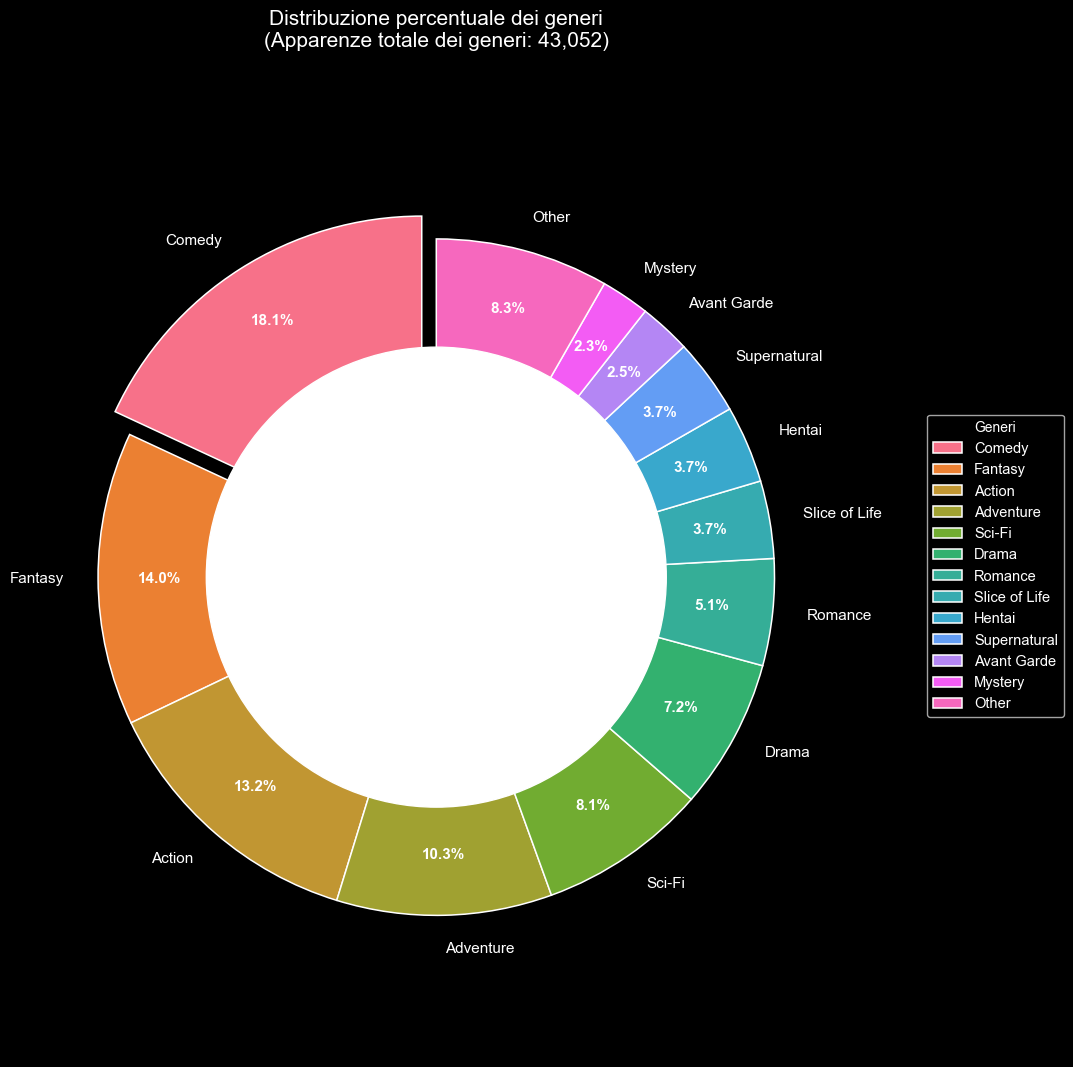

In [6]:
details = df_details.copy()
details = details.dropna(subset=['genres'])
details['genres'] = details['genres'].apply(utils.parse_genres)
# Explode: una riga per ogni genere
genres_df = details.explode('genres')
# Conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()
# Top 12 generi + Other
top_n_pie = 12
top_genres_pie = genre_total.head(top_n_pie)
other_count = genre_total.iloc[top_n_pie:].sum()

if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie

plt.figure(figsize=(11, 11))
colors = sns.color_palette("husl", len(pie_data))

# Explode solo sulla fetta più grande
explode = [0.08 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]

wedges, texts, autotexts = plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},
    textprops={'fontsize': 11}
)

# Stile percentuali
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.title(f"Distribuzione percentuale dei generi\n(Apparenze totale dei generi: {genre_total.sum():,})",fontsize=15, pad=20)
# Effetto donut
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# Legenda
plt.legend(pie_data.index, title="Generi", loc="center left",bbox_to_anchor=(1.15, 0.5), fontsize=10.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

**L'anima del mosaico: la forza delle nicchie**

Il grafico a ciambella ci offre una prospettiva diversa e fondamentale: quella della "biodiversità" del settore. Sebbene i generi dominanti occupino le fette più grandi, la vasta area definita dalle categorie minori rivela la vera magia degli anime. Non è un mercato a senso unico, ma un mosaico composto da centinaia di sfumature diverse che convivono armoniosamente.

**Visione d'insieme: un ecosistema multiforme**

In sintesi, l'equilibrio tra i generi **mainstream** (che garantiscono la stabilità economica) e le innumerevoli **nicchie** (che preservano la vivacità artistica) è il vero segreto del successo globale. Questa distribuzione ci restituisce l'immagine di un ecosistema maturo, dove ogni spettatore, indipendentemente da quanto siano particolari i suoi gusti, potrà sempre trovare una storia originale cucita su misura per lui.

### Come sono cambiati i generi anime nel tempo?

In [7]:
df_gen_evol = df_details.copy()
df_gen_evol = df_gen_evol.dropna(subset=['year'])
df_gen_evol = df_gen_evol[(df_gen_evol['year'] >= 1917) & (df_gen_evol['year'] <= 2024)]
df_gen_evol = df_gen_evol.dropna(subset=['genres'])
df_gen_evol['genres'] = df_gen_evol['genres'].apply(utils.parse_genres)
df_gen_evol['genres'] = df_gen_evol['genres'].apply(lambda g: [gen.strip().title() for gen in g])

# explode generi
genres_df = df_gen_evol.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible=True if genre == "Action" else "legendonly",
            line=dict(width=2.5)
        )
    )
fig.update_layout(
    title="Produzione di anime nel tempo per genere",
    xaxis_title="Anno",
    yaxis_title="Numero di anime rilasciati",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Clicca sui generi per mostrare/ nascondere"
)
fig.show()

Il grafico mostra come i principali generi anime si siano evoluti nel corso degli anni, seguendo traiettorie diverse ma con un andamento comune: una crescita lenta fino agli anni ’70, seguita da un’accelerazione evidente a partire dagli anni ’80. In questa fase, generi come _Action_, _Adventure_, _Comedy_ e _Drama_ iniziano a distinguersi, aumentando progressivamente la loro presenza.
Dopo il 2000, tutte le linee mostrano un incremento più marcato, segno di un’espansione generale dell’industria. In particolare, **Comedy** e **Action** emergono come i generi più dinamici, ma con caratteristiche diverse: la Comedy cresce in modo più rapido e raggiunge valori più elevati, mentre l’Action mantiene un andamento più regolare e costante, confermandosi come uno dei pilastri storici della produzione anime. Il 2017 rappresenta un punto particolarmente significativo: in quell’anno, diversi generi tra cui proprio Comedy e Action  toccano uno dei loro massimi, evidenziando un momento di forte intensificazione produttiva.
Negli anni successivi, alcune curve mostrano una lieve flessione, mentre altre mantengono livelli elevati, suggerendo un settore che continua a essere attivo ma con ritmi più equilibrati rispetto al picco precedente.
Nel complesso, il grafico racconta una storia di crescita condivisa, in cui ogni genere segue il proprio percorso ma contribuisce a un’espansione complessiva dell’animazione giapponese.

## 2. DALLA PRODUZIONE ALLA VALUTAZIONE DEGLI UTENTI

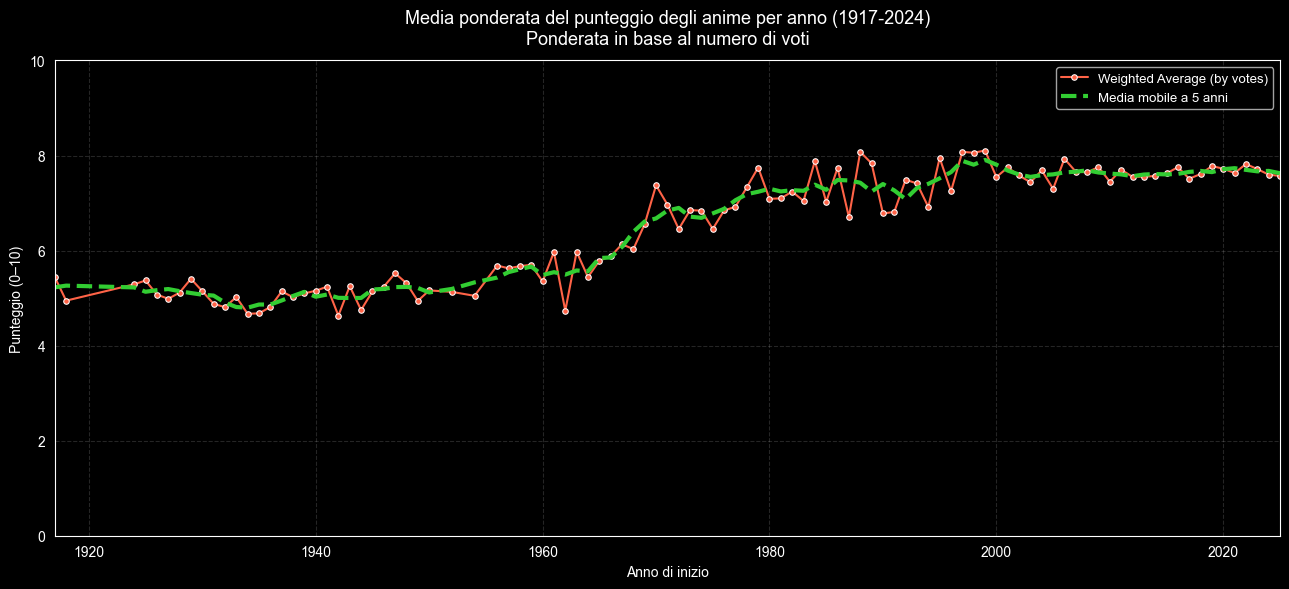

In [8]:
details = df_details.copy()
# filtro per il calcolo della media pesata
df_weighted = details[
    details['score'].notna() &
    details['scored_by'].notna() &
    (details['scored_by'] > 0) &
    details['year'].notna()
].copy()
# limitiamo l'analisi agli anni con dati storicamnete rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]
# calcolo di media dei punteggi, totale dei voti, numero di anime rilasciati
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False
).reset_index()
# Ordina per sicurezza
year_weighted = year_weighted.sort_values('year')
# calcoliamo una media mobile centrata su 5 anni per rendere il trend più leggibile
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(window=5, center=True, min_periods=2).mean()
# visualizzazione
plt.figure(figsize=(13, 6))
# Linea principale: media pesata
sns.lineplot(data=year_weighted,x='year',y='weighted_mean',color='tomato',linewidth=1.5,marker='o',markersize=4,label='Weighted Average (by votes)')
# media mobile
plt.plot(
    year_weighted['year'],
    year_weighted['rolling_weighted'],
    color='limegreen',
    linewidth=3,
    linestyle='--',
    label='Media mobile a 5 anni'
)
plt.title("Media ponderata del punteggio degli anime per anno (1917-2024)\nPonderata in base al numero di voti",fontsize=13,pad=12)
plt.xlabel("Anno di inizio")
plt.ylabel("Punteggio (0–10)")
# limiti degli assi per una scala coerente
plt.xlim(year_weighted['year'].min(), year_weighted['year'].max())
plt.ylim(0, 10)

plt.grid(True, alpha=0.15, linestyle='--')
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.
> **Nota sui dati:** I decenni precedenti al 1960 presentano spesso 1–3 anime per anno e meno di 1.000 voti totali: le medie di quei periodi sono basate su campioni molto ridotti e vanno interpretate con cautela. La media mobile a 5 anni aiuta ad attenuare questi picchi isolati.


### I generi più prodotti sono anche quelli più amati dai fan?

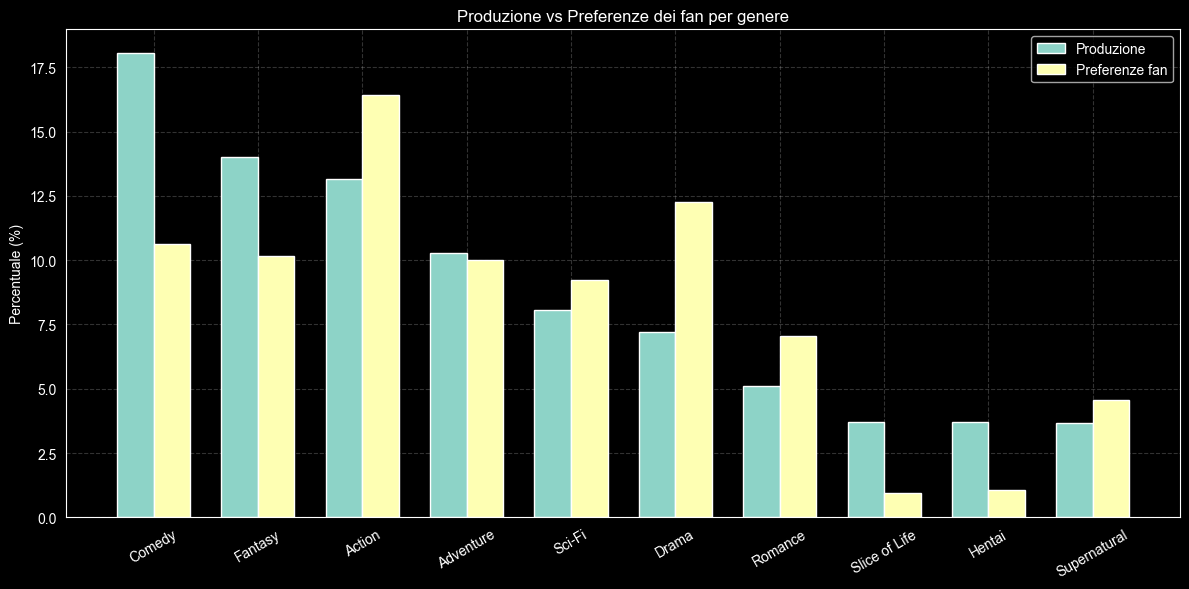

In [9]:
details = df_details.copy().dropna(subset=['genres'])
details['genres'] = details['genres'].apply(utils.parse_genres)
genres_df = details.explode('genres')
favs = df_favs.copy()
production = genres_df['genres'].value_counts()
production_pct = production / production.sum() * 100

favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
favs_count = favs_genres['genres'].value_counts()
favs_pct = favs_count / favs_count.sum() * 100

compare = pd.DataFrame({'Production (%)': production_pct, 'Fan Preferences (%)': favs_pct}).dropna()
compare = compare.sort_values('Production (%)', ascending=False).head(10)

x = np.arange(len(compare))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, compare['Production (%)'], width, label='Produzione')
plt.bar(x + width / 2, compare['Fan Preferences (%)'], width, label='Preferenze fan', )
plt.xticks(x, compare.index, rotation=30)
plt.ylabel("Percentuale (%)")
plt.title("Produzione vs Preferenze dei fan per genere")
plt.legend()
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

Il grafico mette a confronto la percentuale di produzione degli anime per genere con le preferenze dichiarate dai fan, evidenziando in modo immediato le aree di allineamento e quelle di discrepanza. Alcuni generi, come **Comedy** e **Fantasy**, mostrano una produzione molto elevata, ma non sempre corrispondono a un interesse dei fan altrettanto forte, suggerendo una sovraofferta rispetto alla domanda.
Al contrario, generi come **Drama** o **Romance** presentano una distanza più contenuta tra ciò che viene prodotto e ciò che il pubblico preferisce, indicando un equilibrio più stabile. In altri casi, come _Hentai_ o _Slice of Life_, la produzione risulta superiore alle preferenze, mentre generi come Supernatural mostrano un rapporto più armonico tra offerta e gradimento.
Nel complesso, il grafico racconta una dinamica interessante: l’industria tende a investire maggiormente nei generi più versatili e commerciali, mentre le preferenze dei fan risultano più distribuite e talvolta orientate verso generi meno rappresentati. Questa differenza tra produzione e domanda offre uno spunto utile per comprendere come il mercato anime si adatti o talvolta non si adatti alle aspettative del pubblico.
> **Nota sui dati:** Il 32,8 % dei preferiti degli utenti (1,37 M su 4,18 M righe) fa riferimento ad anime non presenti nel file details.csv e viene escluso dall'analisi delle preferenze. Inoltre, il 20,7 % degli anime è privo di tag di genere ed è escluso da entrambi i calcoli.

## 3. LE ORIGINI NARRATIVE DEGLI ANIME

### Da dove nascono gli anime

In [38]:
details = df_details.copy()
details = details[(details['source'].notna()) & (details['source'] != 'Unknown') & (details['source'] != 'Other')]
details['source'] = details['source'].str.strip().str.title()
source_counts = details['source'].value_counts().reset_index()
source_counts.columns = ['source', 'count']

fig = px.treemap(
    source_counts,
    path=['source'],
    values='count',
    color='count',
    color_continuous_scale='Blues',
    title='Da dove nascono gli anime?',
)
fig.update_traces(
    textinfo='label+value+percent root',
    textfont_size=14,
    hovertemplate='<b>%{label}</b><br>Anime: %{value:,}<br>%{percentRoot:.1%}<extra></extra>'
)
fig.update_layout(height=520, margin=dict(t=50, l=10, r=10, b=10),
                  coloraxis_colorbar=dict(title='N. anime'))
fig.show()

Il grafico mostra la distribuzione delle principali **fonti di ispirazione** degli anime, evidenziando da quali media o opere originali nasce la produzione animata giapponese.

Il dato più evidente è la **forte predominanza delle opere Original**, che rappresentano la quota maggiore. Questo suggerisce che l’industria anime mantiene una notevole capacità creativa autonoma, producendo contenuti non direttamente derivati da altri media.

Subito dopo emergono gli adattamenti da **Manga**, che confermano il ruolo centrale di questo medium come serbatoio narrativo per l’animazione giapponese. Manga e anime risultano quindi profondamente interconnessi, sia dal punto di vista artistico che industriale.

Le altre categorie (come **Light Novel**, **Game**, **Visual Novel** e **Web Manga**) hanno una presenza più contenuta ma significativa, indicando una crescente tendenza alla contaminazione tra media diversi. Questo fenomeno riflette l’evoluzione del consumo culturale, sempre più crossmediale.

Nel complesso, il grafico racconta un’industria che combina **creatività originale** e **adattamento strategico**, bilanciando innovazione e sicurezza commerciale.
> **Nota sui dati:** Il 14,2 % degli anime (4.120 titoli) ha fonte classificata come "Unknown", "Other" o non disponibile ed è escluso dal grafico. La distribuzione rappresenta l'85,8 % del catalogo.


## 4. POPOLARITA' E IMPATTO CULTURALE

### In quali anni emergono gli anime più popolari?

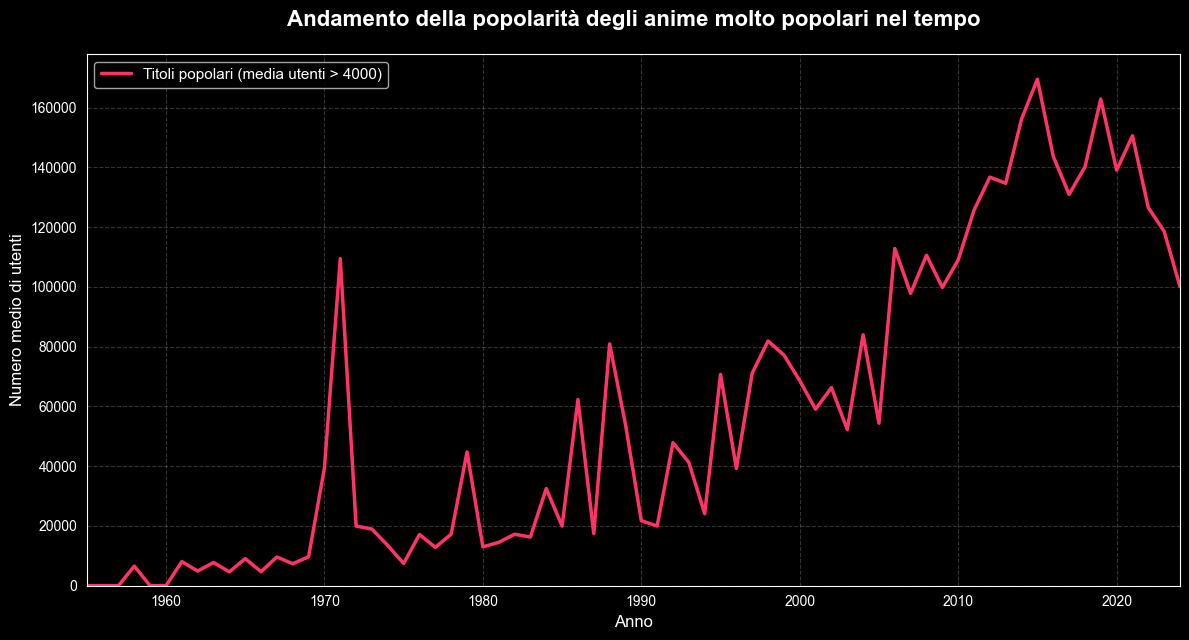

In [11]:
details = df_details.copy()

popular_pop = (details[details['members'] > 4000].groupby('year')['members'].mean().reindex(range(1955, 2025), fill_value=0).reset_index())

plt.figure(figsize=(12, 6.5))
plt.plot(
    popular_pop['year'],
    popular_pop['members'],
    color='#FF3366',
    linewidth=2.5,
    label='Titoli popolari (media utenti > 4000)'
)

plt.title('Andamento della popolarità degli anime molto popolari nel tempo',
          fontsize=16,
          fontweight='bold',
          pad=20)

plt.xlabel('Anno', fontsize=12)
plt.ylabel('Numero medio di utenti', fontsize=12)
plt.grid(True, alpha=0.2, linestyle='--')
plt.legend(fontsize=11, loc='upper left')
plt.xlim(1955, 2024)
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

Il grafico mostra l’andamento della popolarità degli anime più seguiti nel corso di diversi decenni, misurata attraverso il numero medio di membri. La linea evidenzia un percorso irregolare ma significativo: nei primi anni la popolarità rimane contenuta, con oscillazioni limitate e valori relativamente bassi.
A partire dagli anni ’70 compaiono i primi picchi, seguiti da un nuovo aumento verso la fine degli anni ’80, segno di un interesse crescente e di titoli che iniziano a raggiungere un pubblico più ampio. Tuttavia, è dall’inizio degli anni 2000 che la curva cambia ritmo in modo evidente: la popolarità cresce rapidamente, raggiungendo il suo massimo tra la metà e la fine degli anni 2010.
Dopo questo periodo di forte espansione, la linea mostra una diminuzione verso il 2020, suggerendo una fase di rallentamento dopo anni di crescita intensa. Nonostante ciò, i valori rimangono comunque molto più alti rispetto alle decadi precedenti, indicando un livello di interesse complessivo ancora elevato.
Nel complesso, il grafico racconta una storia di progressiva affermazione: da un fenomeno di nicchia, la popolarità degli anime più seguiti cresce fino a diventare un elemento centrale della cultura contemporanea, con cicli di espansione e assestamento che riflettono l’evoluzione del pubblico e dell’industria.
> **Nota sui dati:** La soglia di 4.000 membri è arbitraria e include il 34,4 % del catalogo. Gli anni 1955–1960 in cui nessun anime supera tale soglia vengono rappresentati come 0: non come dato mancante, ma come assenza di titoli sufficientemente seguiti in quel periodo.

### Gli anime più amati dagli utenti

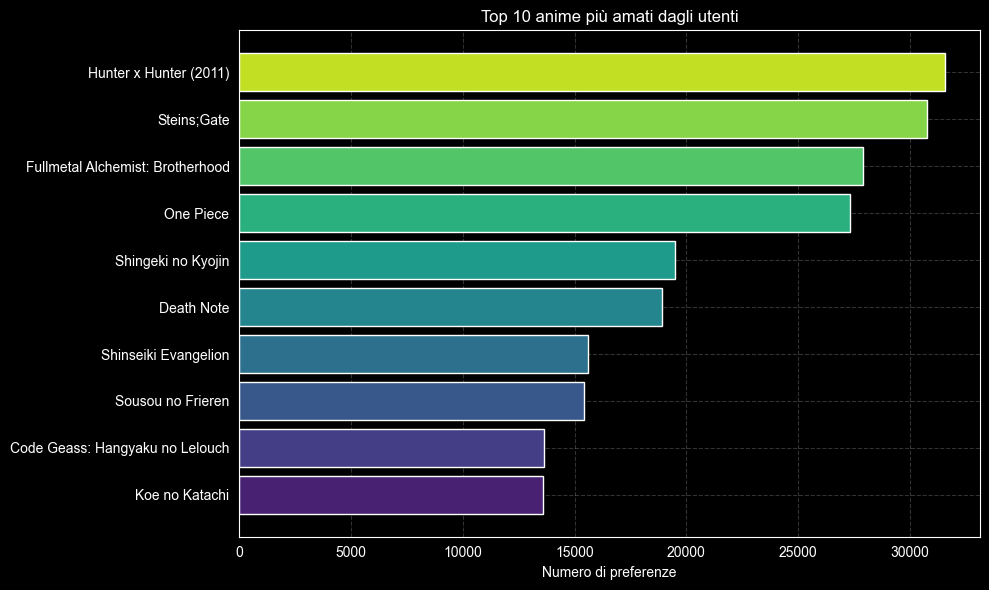

In [12]:
details = df_details.copy()
favs = df_favs[df_favs["fav_type"] == "anime"].copy()
valid_mal_ids = details['mal_id'].unique()
filtered_favs = favs[favs['mal_id'].isin(valid_mal_ids)]
top_anime = (filtered_favs['mal_id'].value_counts().head(10).reset_index())
top_anime.columns = ['mal_id', 'fav_count']
top_anime = pd.merge(top_anime, details[['mal_id', 'title']], on='mal_id', how='inner')
# Sort for horizontal bar chart
top_anime = top_anime.sort_values('fav_count')
plt.figure(figsize=(10, 6))
_pal = sns.color_palette('viridis', len(top_anime))
plt.barh(top_anime['title'], top_anime['fav_count'], color=_pal)
plt.xlabel("Numero di preferenze")
plt.title("Top 10 anime più amati dagli utenti")
plt.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()

Il grafico mostra quali anime hanno conquistato davvero il cuore degli utenti, non solo la loro attenzione.

In cima alla classifica troviamo **Hunter x Hunter (2011)** con oltre 31.500 preferenze, seguito a strettissimo giro da **Steins;Gate** con circa 30.700. Nonostante appartengano a generi molto diversi — avventura fantasy il primo, sci-fi il secondo — entrambi condividono una narrazione intensa e personaggi profondamente caratterizzati.

**Fullmetal Alchemist: Brotherhood** e **One Piece** si collocano poco sotto, attorno alle 27.000–28.000 preferenze, formando insieme ai primi due un gruppo di testa ben distinto dal resto della classifica.

Dopo il quarto posto si nota infatti un calo netto: si scende a circa 19.000 preferenze con **Shingeki no Kyojin**, e da lì i valori continuano a calare gradualmente fino a **Code Geass** e **Koe no Katachi**, che si attestano attorno alle 13.500–13.600 preferenze.

In sintesi, la community premia storie con **narrazione emotiva, personaggi memorabili e generi misti** — azione, dramma, fantasy e sci-fi. I titoli in cima non sono i più recenti né i più lunghi, ma quelli che hanno lasciato il segno più profondo.

## Distribuzione dei voti per anime

Le valutazioni non sono solo medie: ogni anime ha una distribuzione di voti che racconta molto di più. Un anime polarizzante raccoglie sia 1 che 10; uno consistente ha voti concentrati attorno a 8–9. La distribuzione rivela la qualità percepita e l'unanimità del giudizio

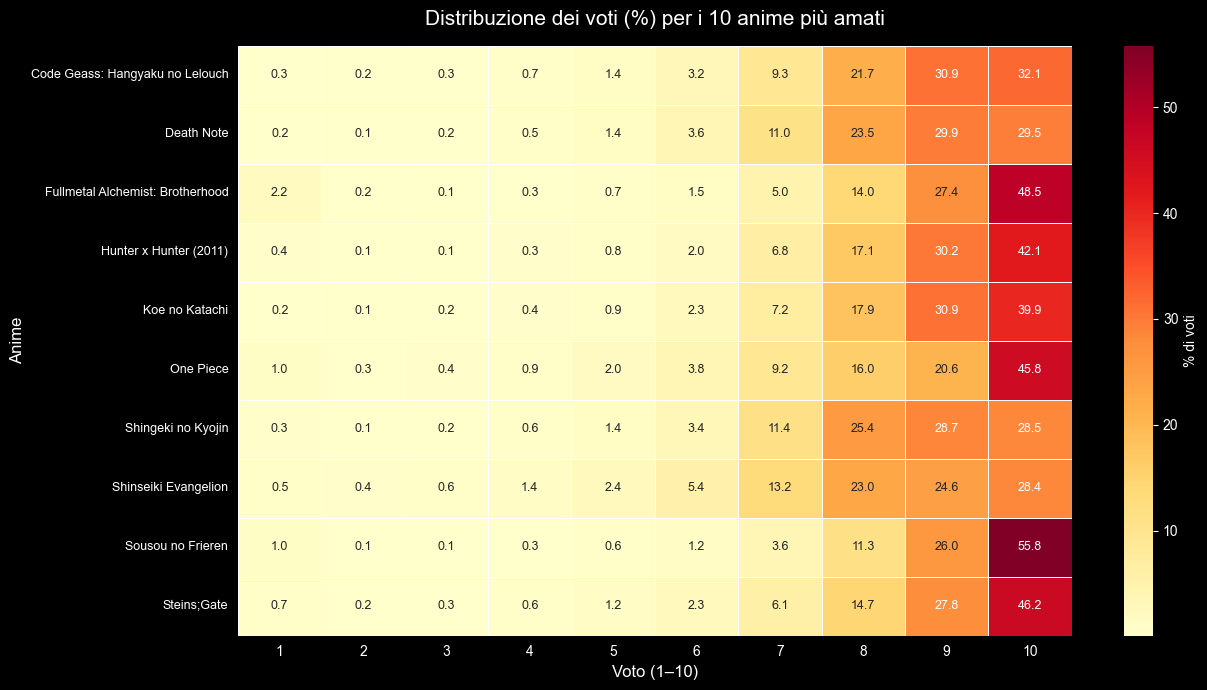

In [13]:
stats = df_stats.copy()
favs = df_favs[df_favs["fav_type"] == "anime"].copy()
valid_mal_ids = df_details["mal_id"].unique()
filtered_favs = favs[favs["mal_id"].isin(valid_mal_ids)]
top10_ids  = filtered_favs["mal_id"].value_counts().head(10).index
score_cols = [f"score_{i}_votes" for i in range(1, 11)]
top_stats = stats[stats["mal_id"].isin(top10_ids)][["mal_id"] + score_cols].copy()
top_stats = pd.merge(
    top_stats, df_details[["mal_id", "title"]], on="mal_id", how="left"
)
# normalizza a percentuale per riga
top_stats[score_cols] = (
    top_stats[score_cols]
    .div(top_stats[score_cols].sum(axis=1), axis=0) * 100
)

heatmap_data = top_stats.set_index("title")[score_cols].copy()
heatmap_data.columns = list(range(1, 11))

fig, ax = plt.subplots(figsize=(13, 7))


sns.heatmap(
    heatmap_data,
    annot=True, fmt=".1f", cmap="YlOrRd",
    linewidths=0.5, ax=ax,
    cbar_kws={"label": "% di voti"},
    annot_kws={"size": 9}
)
ax.set_title(
    "Distribuzione dei voti (%) per i 10 anime più amati", fontsize=15, pad=15
)
ax.set_xlabel("Voto (1–10)", fontsize=12)
ax.set_ylabel("Anime", fontsize=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

La heatmap rivela la 'personalità' di ciascun anime attraverso i voti. Alcuni titoli mostrano una forte concentrazione di voti alti (8–10), segno di un pubblico coeso e soddisfatto. Altri presentano una distribuzione più ampia, con presenze significative anche a voti bassi, tipica delle opere polarizzanti che suscitano reazioni forti in entrambe le direzioni

### One Piece: qualità percepita e popolarità tra gli utenti


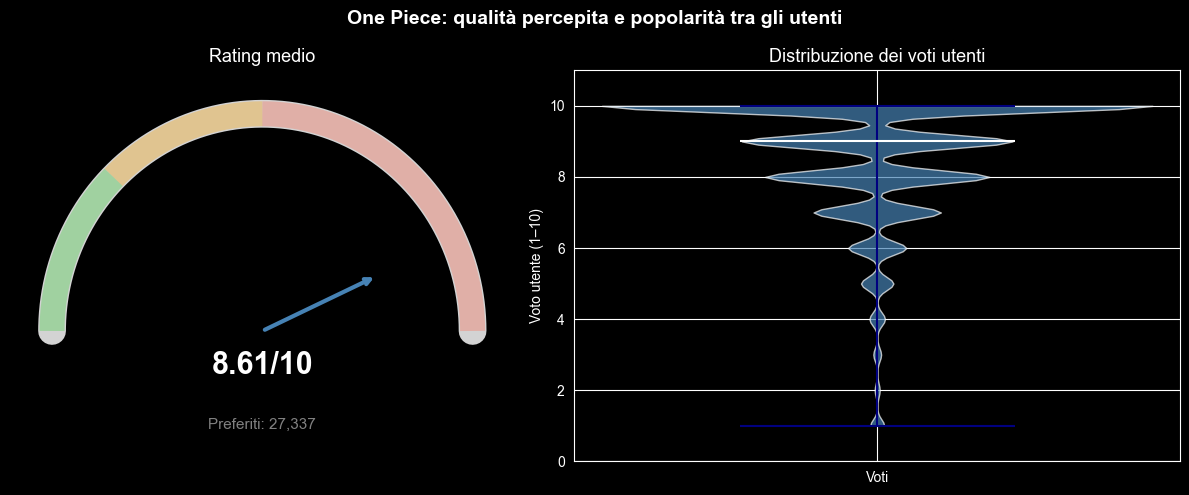

In [14]:
details = df_details.copy()
ratings = df_ratings.copy()
anime_title = 'One Piece'
mal_id = details[details['title'] == anime_title]['mal_id'].iloc[0]
anime_ratings = ratings[(ratings['anime_id'] == mal_id) & (ratings['score'] > 0)]['score']
avg_user_rating = anime_ratings.mean()
fav_count = favs[favs['mal_id'] == mal_id].shape[0]

fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.2])

#Gauge
ax0 = fig.add_subplot(gs[0])
theta = np.linspace(0, np.pi, 300)
ax0.plot(np.cos(theta), np.sin(theta), color='lightgray', lw=20, solid_capstyle='round')

for start, end, color in [
    (0,    0.5,  '#ff634750'),
    (0.5,  0.75, '#ffa50050'),
    (0.75, 1.0,  '#32cd3250')
]:
    t = np.linspace(start * np.pi, end * np.pi, 100)
    ax0.plot(np.cos(t), np.sin(t), lw=18, color=color, solid_capstyle='butt')

angle = np.pi * (1 - avg_user_rating / 10)
ax0.annotate('', xy=(0.6 * np.cos(angle), 0.6 * np.sin(angle)), xytext=(0, 0),
             arrowprops=dict(arrowstyle='->', color='steelblue', lw=3))

ax0.text(0, -0.2,  f'{avg_user_rating:.2f}/10', ha='center', fontsize=22, fontweight='bold')
ax0.text(0, -0.45, f'Preferiti: {fav_count:,}', ha='center', fontsize=11, color='gray')
ax0.set_xlim(-1.2, 1.2)
ax0.set_ylim(-0.6, 1.2)
ax0.axis('off')
ax0.set_title('Rating medio', fontsize=13)

#Violin
ax1 = fig.add_subplot(gs[1])
parts = ax1.violinplot(anime_ratings, positions=[1], showmedians=True, showextrema=True)

parts['bodies'][0].set_facecolor('steelblue')
parts['bodies'][0].set_alpha(0.7)
parts['cmedians'].set_color('white')
parts['cbars'].set_color('navy')
parts['cmins'].set_color('navy')
parts['cmaxes'].set_color('navy')

ax1.set_xticks([1])
ax1.set_xticklabels(['Voti'])
ax1.set_ylabel('Voto utente (1–10)')
ax1.set_ylim(0, 11)
ax1.set_title('Distribuzione dei voti utenti', fontsize=13)

plt.suptitle('One Piece: qualità percepita e popolarità tra gli utenti', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Questo grafico analizza il caso di **One Piece**, mettendo a confronto la **qualità percepita dagli utenti** (rating medio) e la **popolarità**, misurata tramite il numero di preferenze (favs).

Il primo grafico evidenzia come One Piece presenti una popolarità estremamente elevata, normalizzata su una scala comparabile con il rating. Al contrario, il rating medio degli utenti risulta più moderato. Questo squilibrio suggerisce che la popolarità non dipende esclusivamente dal giudizio medio, ma anche da fattori come la longevità della serie, l’affezione emotiva del pubblico e l’impatto culturale nel tempo.

Il secondo grafico mostra la **distribuzione dei voti degli utenti**. Si osserva una forte concentrazione di voti alti (8–10), accompagnata però da una presenza significativa di voti bassi. Questo fenomeno è tipico delle opere molto popolari: attirano un pubblico ampio e diversificato, generando valutazioni più polarizzate.

Nel complesso, One Piece emerge come un esempio emblematico di come un anime possa essere **massicciamente seguito e amato**, pur non avendo un consenso uniforme sul piano della valutazione numerica.


### Gli anime con il rating più basso: cosa non ha convinto il pubblico

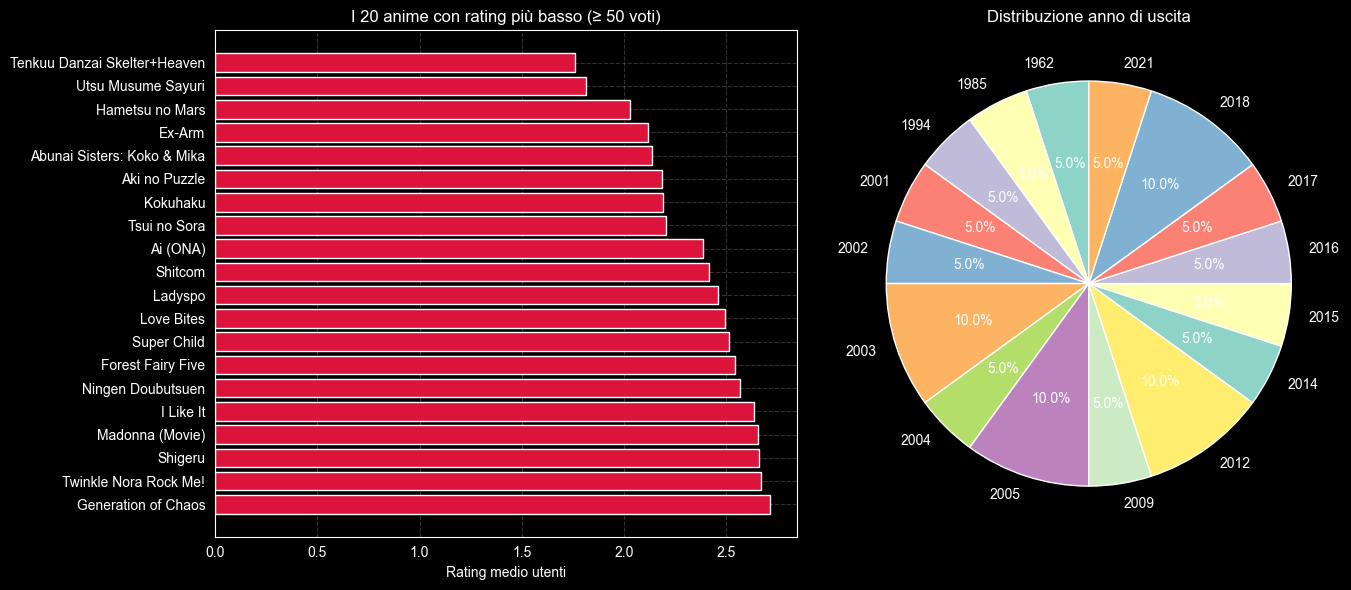

In [15]:
ratings_clean = df_ratings.copy()
ratings_clean = ratings_clean[ratings_clean["score"] > 0]
rating_stats = (ratings_clean.groupby("anime_id").agg(avg_user_score=("score", "mean"),num_votes=("score", "count")).reset_index())
# tieni solo anime con almeno 50 voti
rating_stats = rating_stats[rating_stats["num_votes"] >= 50]
anime_scores = pd.merge(
    rating_stats,
    df_details[["mal_id", "title", "year", "popularity"]],
    left_on="anime_id",
    right_on="mal_id",
    how="inner"
)
# filtro anno SENZA sovrascrivere tutto
anime_scores = anime_scores[(anime_scores["year"] >= 1917) & (anime_scores["year"] <= 2024)]
worst_20 = (anime_scores.sort_values("avg_user_score", ascending=True).head(20))
year_counts = worst_20["year"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh( worst_20["title"],worst_20["avg_user_score"],color="crimson")
axes[0].invert_yaxis()
axes[0].set_xlabel("Rating medio utenti")
axes[0].set_title("I 20 anime con rating più basso (≥ 50 voti)")
axes[0].grid(True, alpha=0.2, linestyle='--')

axes[1].pie(
    year_counts.values,
    labels=year_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Distribuzione anno di uscita")

plt.tight_layout()
plt.show()

Il grafico a sinistra presenta i venti anime con il rating medio più basso tra quelli che hanno ricevuto almeno cinquanta voti. La lista mostra una concentrazione di titoli che hanno ottenuto valutazioni particolarmente negative, con punteggi che rimangono molto bassi lungo tutta la classifica. La presenza di opere come Skelter+Heaven, Ex-Arm o Abunai Sisters evidenzia come alcuni progetti siano diventati emblematici di produzioni percepite come poco riuscite dal pubblico.
Accanto a questo, il grafico a torta sulla destra mostra la distribuzione degli anni di uscita di questi titoli. La varietà delle date che spaziano dagli anni ’60 fino agli anni più recenti indica che i prodotti mal valutati non appartengono a un’unica epoca, ma si distribuiscono lungo più decenni. Tuttavia, si nota una concentrazione maggiore in alcuni periodi, come i primi anni 2000 e la seconda metà degli anni 2010, suggerendo fasi in cui sono stati pubblicati più titoli che non hanno incontrato il favore degli utenti.
Nel complesso, i due grafici raccontano una storia complementare: da un lato una selezione di opere che rappresentano il “fondo classifica” delle valutazioni, dall’altro una distribuzione temporale che mostra come la scarsa ricezione non sia legata a un’epoca specifica, ma sia un fenomeno ricorrente nel tempo. Questo insieme offre una panoramica utile per comprendere come, accanto ai grandi successi, l’industria abbia prodotto anche titoli che non sono riusciti a soddisfare le aspettative del pubblico.

# Most recommended anime

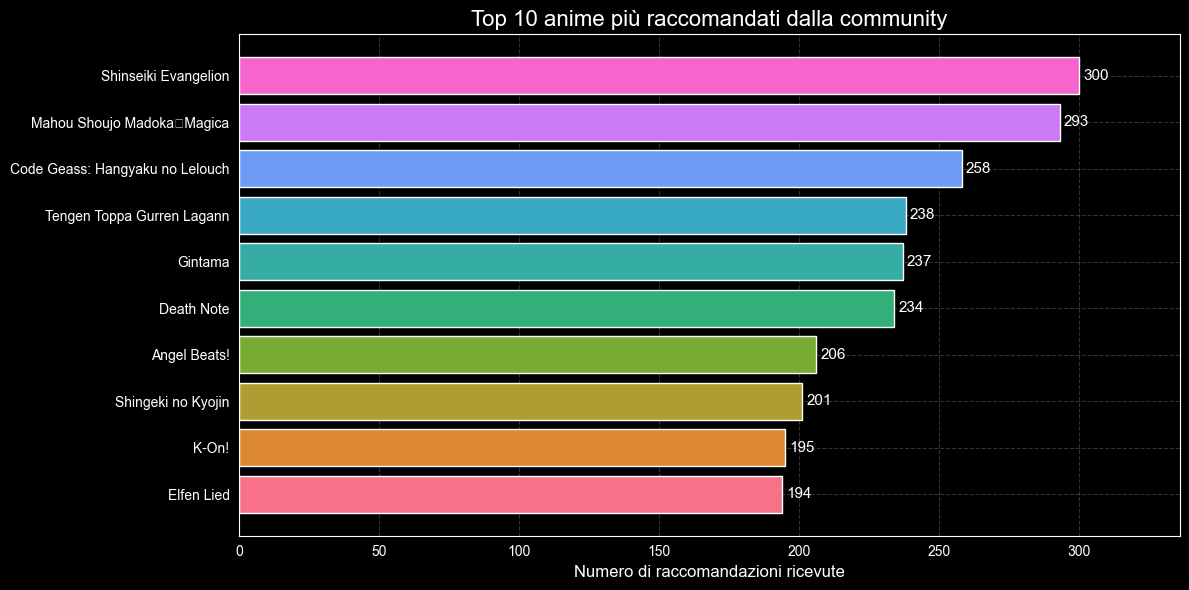

In [16]:
recs = df_recommendations.copy()
details = df_details.copy()
# top 10 anime per numero di raccomandazioni ricevute
most_recommended = (
    recs["recommendation_mal_id"]
    .value_counts()
    .head(10)
    .reset_index()
)
most_recommended.columns = ["mal_id", "rec_count"]
most_recommended = (
    pd.merge(most_recommended, details[["mal_id", "title"]], on="mal_id", how="left")
    .sort_values("rec_count", ascending=True)
)

palette = sns.color_palette("husl", len(most_recommended))
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(most_recommended["title"], most_recommended["rec_count"], color=palette)
ax.set_title("Top 10 anime più raccomandati dalla community", fontsize=16)
ax.set_xlabel("Numero di raccomandazioni ricevute", fontsize=12)
ax.bar_label(bars, padding=3, fontsize=11)
ax.set_xlim(0, most_recommended["rec_count"].max() * 1.12)
plt.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()

Gli anime più raccomandati non coincidono necessariamente con quelli più popolari o meglio votati. Sono titoli che i fan considerano 'fondamentali' del medium: opere di riferimento suggerite come punto d'ingresso o come passo successivo dopo aver apprezzato qualcosa di simile. La loro presenza in cima a questa classifica riflette il peso che hanno nell'immaginario collettivo della community.

## 5. I PERSONAGGI

Dopo aver osservato gli anime più popolari, il passo successivo è capire **dove si concentra l’attenzione dei fan**.

### Personaggi principali e secondari: quantità e notorietà a confronto

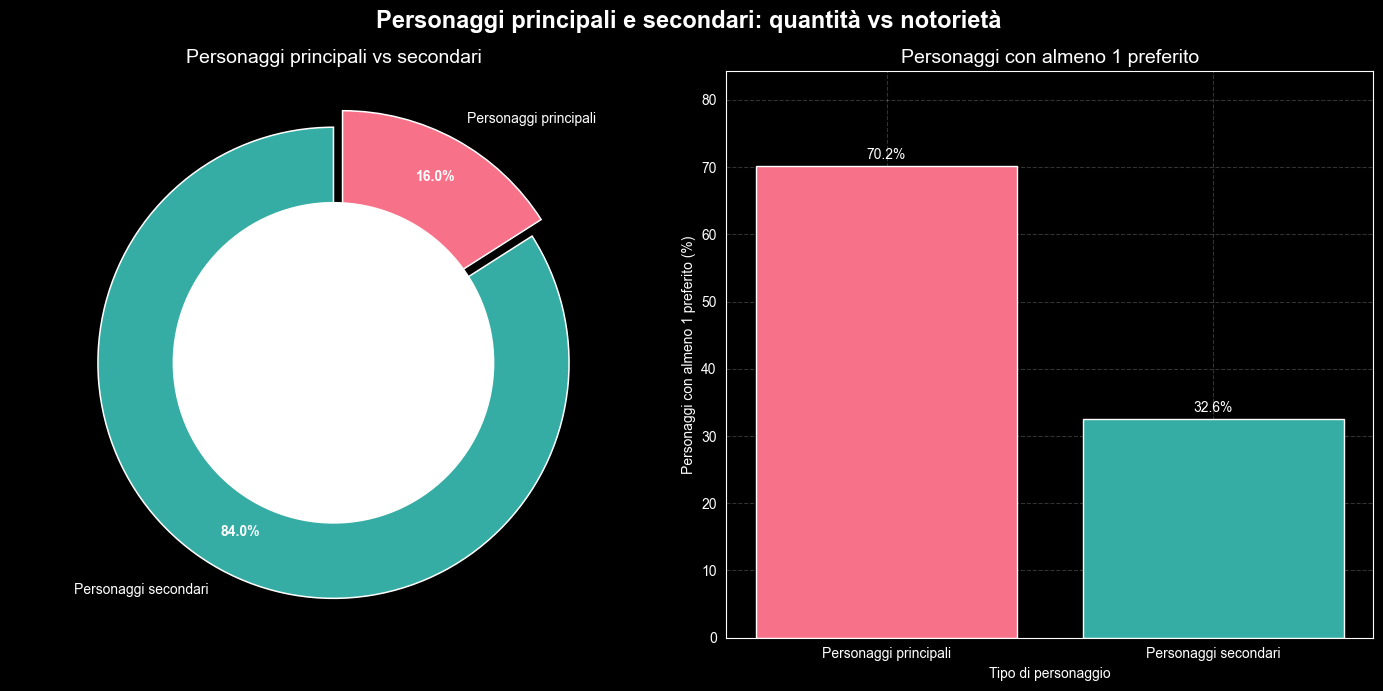

In [17]:
# preparazione dati
character_popularity = (
    df_characters_anime_works
    .loc[lambda df: df["role"].isin(["Main", "Supporting"]), ["character_mal_id", "role"]]
    .drop_duplicates()
    .groupby("character_mal_id")
    .filter(lambda x: x["role"].nunique() == 1)
    .drop_duplicates("character_mal_id")
    .merge(df_characters[["character_mal_id", "favorites"]], on="character_mal_id")
)
labels = {"Main": "Personaggi principali", "Supporting": "Personaggi secondari"}
order = ["Personaggi principali", "Personaggi secondari"]
character_popularity["role_group"] = character_popularity["role"].replace(labels)
character_popularity["has_favorites"] = character_popularity["favorites"] > 0

# tabelle
main_support_table = (
    character_popularity.groupby("role_group")["character_mal_id"]
    .nunique()
    .reindex(order)
)

popularity_table = (
    character_popularity.groupby("role_group")
    .agg(
        total=("character_mal_id", "nunique"),
        with_favourites=("has_favorites", "sum")
    )
    .reindex(order)
)

popularity_table["share"] = (
    popularity_table["with_favourites"] / popularity_table["total"] * 100
).round(1)

# grafico
plt.figure(figsize=(14, 7))
colors = sns.color_palette("husl", 2)

plt.subplot(1, 2, 1)
wedges, texts, autotexts = plt.pie(
    main_support_table,
    labels=main_support_table.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    explode=[0.08, 0],
    pctdistance=0.82,
    wedgeprops={"edgecolor": "white", "linewidth": 1.1}
)

for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")

plt.gca().add_artist(plt.Circle((0, 0), 0.68, fc="white"))
plt.title("Personaggi principali vs secondari", fontsize=14)
plt.axis("equal")

plt.subplot(1, 2, 2)
bars = plt.bar(popularity_table.index, popularity_table["share"], color=colors)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha="center", fontsize=10)

plt.title("Personaggi con almeno 1 preferito", fontsize=14)
plt.xlabel("Tipo di personaggio")
plt.ylabel("Personaggi con almeno 1 preferito (%)")
plt.ylim(0, popularity_table["share"].max() * 1.2)
plt.grid(True, alpha=0.2, linestyle='--')

plt.suptitle("Personaggi principali e secondari: quantità vs notorietà", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

Il grafico confronta personaggi principali e secondari da due prospettive: quanti sono e quanto spesso ricevono almeno un preferito.
La distinzione è importante perché la quantità non coincide sempre con la notorietà.

I personaggi secondari possono essere più numerosi, ma i **protagonisti tendono ad avere maggiore visibilità e a costruire un legame più diretto con i fan**.

## Personaggi e soprannomi

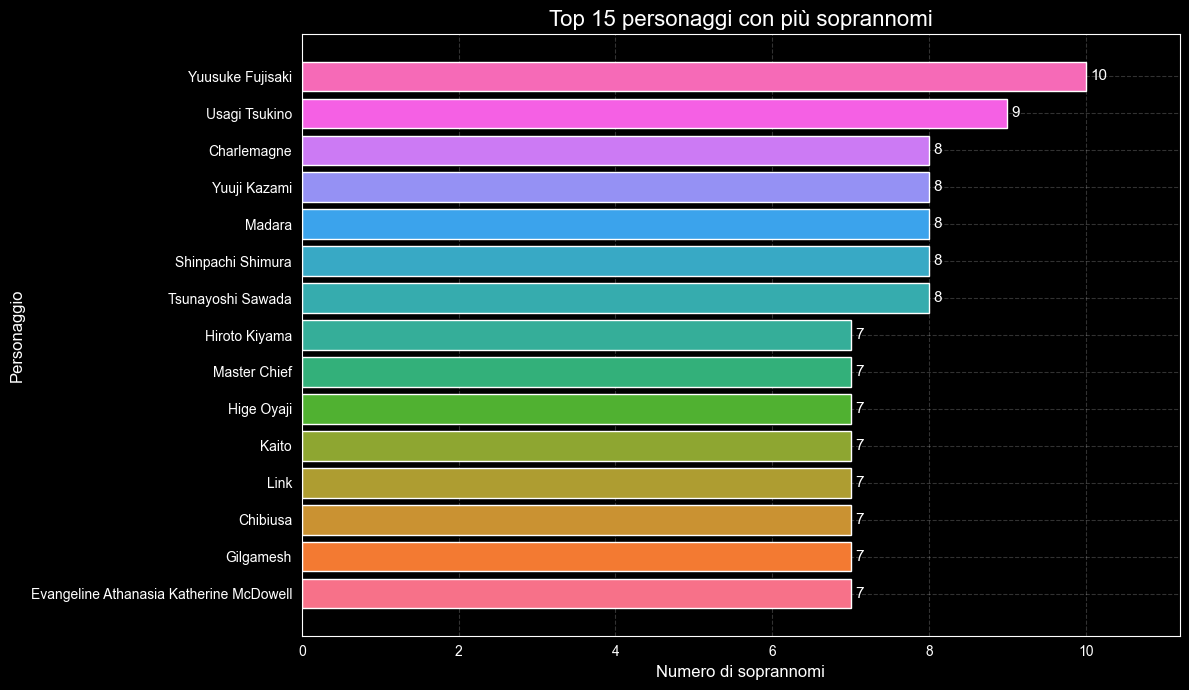

In [18]:
nicknames  = df_character_nicknames.copy()
characters = df_characters.copy()

nickname_counts = (
    nicknames.groupby("character_mal_id")
    .size()
    .reset_index(name="nickname_count")
)

top_nicknames = (
    pd.merge(
        nickname_counts.nlargest(15, "nickname_count"),
        characters[["character_mal_id", "name", "favorites"]],
        on="character_mal_id", how="left"
    )
    .sort_values("nickname_count", ascending=True)
)

palette = sns.color_palette("husl", len(top_nicknames))
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(top_nicknames["name"], top_nicknames["nickname_count"], color=palette)
ax.set_title("Top 15 personaggi con più soprannomi", fontsize=16)
ax.set_xlabel("Numero di soprannomi", fontsize=12)
ax.set_ylabel("Personaggio", fontsize=12)
ax.bar_label(bars, padding=3, fontsize=11)
ax.set_xlim(0, top_nicknames["nickname_count"].max() * 1.12)
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

I personaggi con più soprannomi sono spesso protagonisti di serie di grande successo o caratterizzati da tratti molto riconoscibili. La molteplicità dei nomi riflette la creatività della community: ogni soprannome è una forma di appropriazione affettuosa, un modo in cui i fan fanno propri i personaggi che amano.

## 6. I DOPPIATORI E LINGUE: LE VOCI DIETRO GLI ANIME

Un personaggio non vive solo attraverso il disegno o la storia: **vive anche attraverso la voce**.
Il doppiaggio dà identità ai personaggi, li rende riconoscibili e permette agli anime di arrivare a pubblici diversi.

## Quanti doppiatori hanno gli anime più amati?

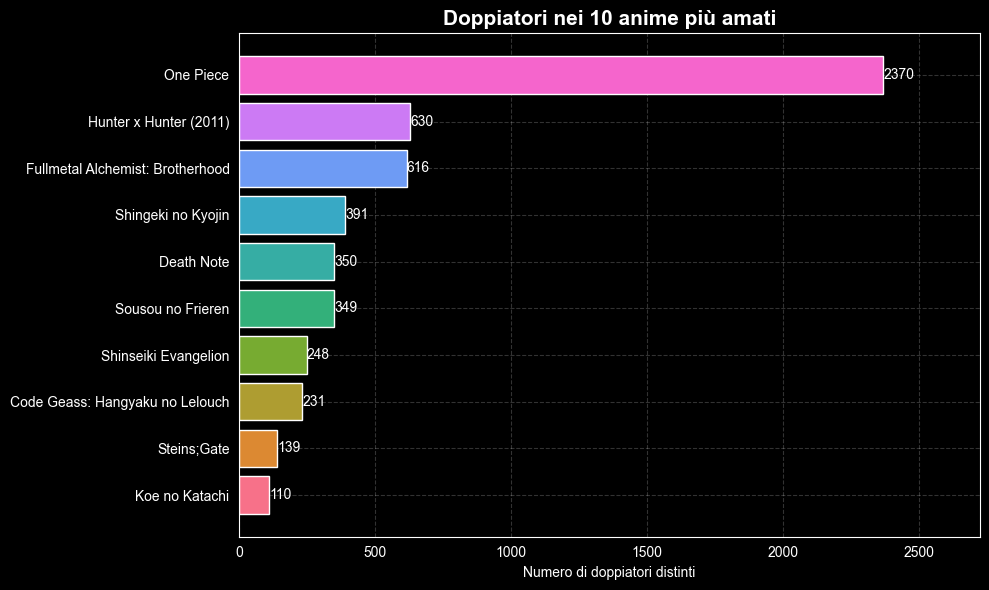

In [19]:
details = df_details.copy()
favs = df_favs[df_favs["fav_type"] == "anime"].copy()
voice_works = df_person_voice_works.copy()

top_anime_voice = (
    favs[favs["mal_id"].isin(details["mal_id"])]["mal_id"]
    .value_counts()
    .head(10)
    .reset_index(name="fav_count")
    .rename(columns={"index": "mal_id"})
    .merge(details[["mal_id", "title"]], on="mal_id")
    .merge(
        voice_works.groupby("anime_mal_id")["person_mal_id"]
        .nunique()
        .reset_index(name="distinct_voice_actors"),
        left_on="mal_id",
        right_on="anime_mal_id",
        how="left"
    )
    .fillna({"distinct_voice_actors": 0})
    .sort_values("distinct_voice_actors")
)

top_anime_voice["distinct_voice_actors"] = top_anime_voice["distinct_voice_actors"].astype(int)

plt.figure(figsize=(10, 6))
colors = sns.color_palette("husl", len(top_anime_voice))

bars = plt.barh(
    top_anime_voice["title"],
    top_anime_voice["distinct_voice_actors"],
    color=colors
)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontsize=10)

plt.title("Doppiatori nei 10 anime più amati", fontsize=15, fontweight="bold")
plt.xlabel("Numero di doppiatori distinti")
plt.ylabel("")
plt.grid(True, alpha=0.2, linestyle='--')
plt.xlim(0, top_anime_voice["distinct_voice_actors"].max() * 1.15)
plt.tight_layout()
plt.show()

In questo grafico ho voluto rappresentare quanti doppiatori hanno le anime più amate (prese dal grafico Top 10 Anime più amate)).
Il numero di doppiatori aiuta a vedere la **complessità produttiva dietro gli anime più popolari**.
Secondo me questo risultato è interessante perché fa capire che non sempre gli anime più popolari sono quelle che richiedono un maggiori numero di lavoro, notiamo infatti che One Piece emerge rispetto a Hunter x Hunter o altre anime più amate.

Dopo aver visto quali anime richiedono il maggior numero di voci, il passo successivo è osservare il fenomeno dal punto di vista opposto: non più gli anime, ma i singoli doppiatori, per capire quali professionisti hanno interpretato il maggior numero di personaggi distinti.

## Top 10 doppiatori per personaggi distinti doppiati

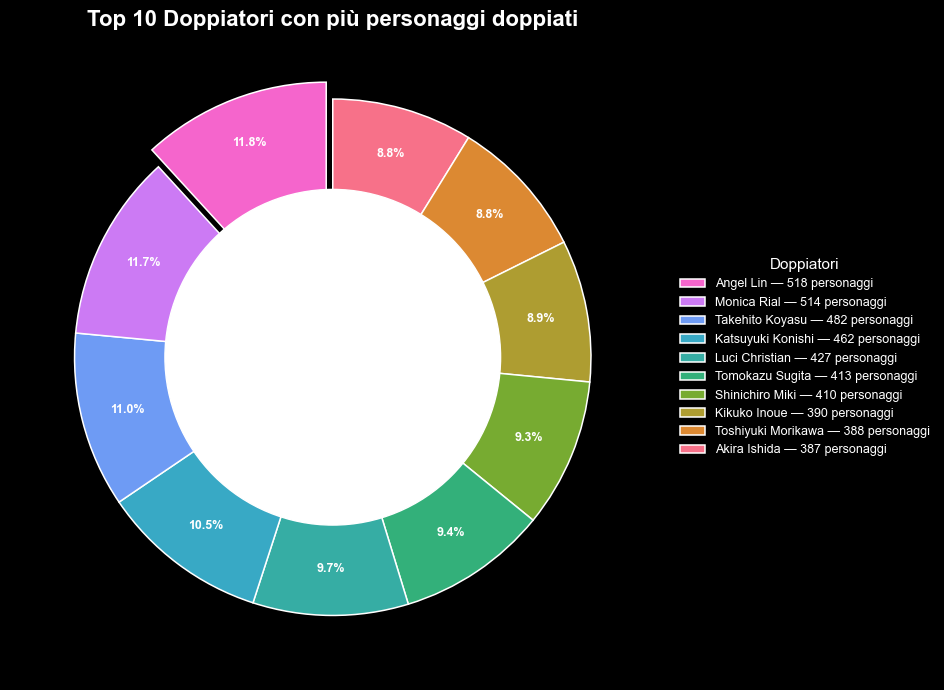

In [20]:
voice_works = df_person_voice_works.copy()
person_details = df_person_details.copy()

top_voice_actors = (
    voice_works.groupby("person_mal_id")["character_mal_id"]
    .nunique()
    .reset_index(name="characters")
    .sort_values("characters", ascending=False)
    .head(10)
    .merge(person_details[["person_mal_id", "name"]], on="person_mal_id", how="left")
    .sort_values("characters")
)

plt.figure(figsize=(9, 7))
colors = sns.color_palette("husl", len(top_voice_actors))

explode = [
    0.07 if x == top_voice_actors["characters"].max() else 0
    for x in top_voice_actors["characters"]
]

wedges, texts, autotexts = plt.pie(
    top_voice_actors["characters"],
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={"edgecolor": "white", "linewidth": 1.1}
)

for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
    t.set_fontsize(9)

plt.gca().add_artist(plt.Circle((0, 0), 0.65, fc="white"))

labels = [
    f"{name} — {value} personaggi"
    for name, value in zip(top_voice_actors["name"][::-1], top_voice_actors["characters"][::-1])
]

plt.legend(
    wedges[::-1],
    labels,
    title="Doppiatori",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=11
)

plt.title("Top 10 Doppiatori con più personaggi doppiati", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Il grafico mostra i 10 doppiatori che hanno interpretato il maggior numero di personaggi distinti. Si nota che alcuni professionisti hanno lavorato su centinaia di ruoli diversi, confermando quanto il doppiaggio sia una parte molto rilevante dell’industria anime.

Il doppiaggio permette agli anime di superare i confini linguistici e raggiungere community diverse.

## Le lingue più doppiate

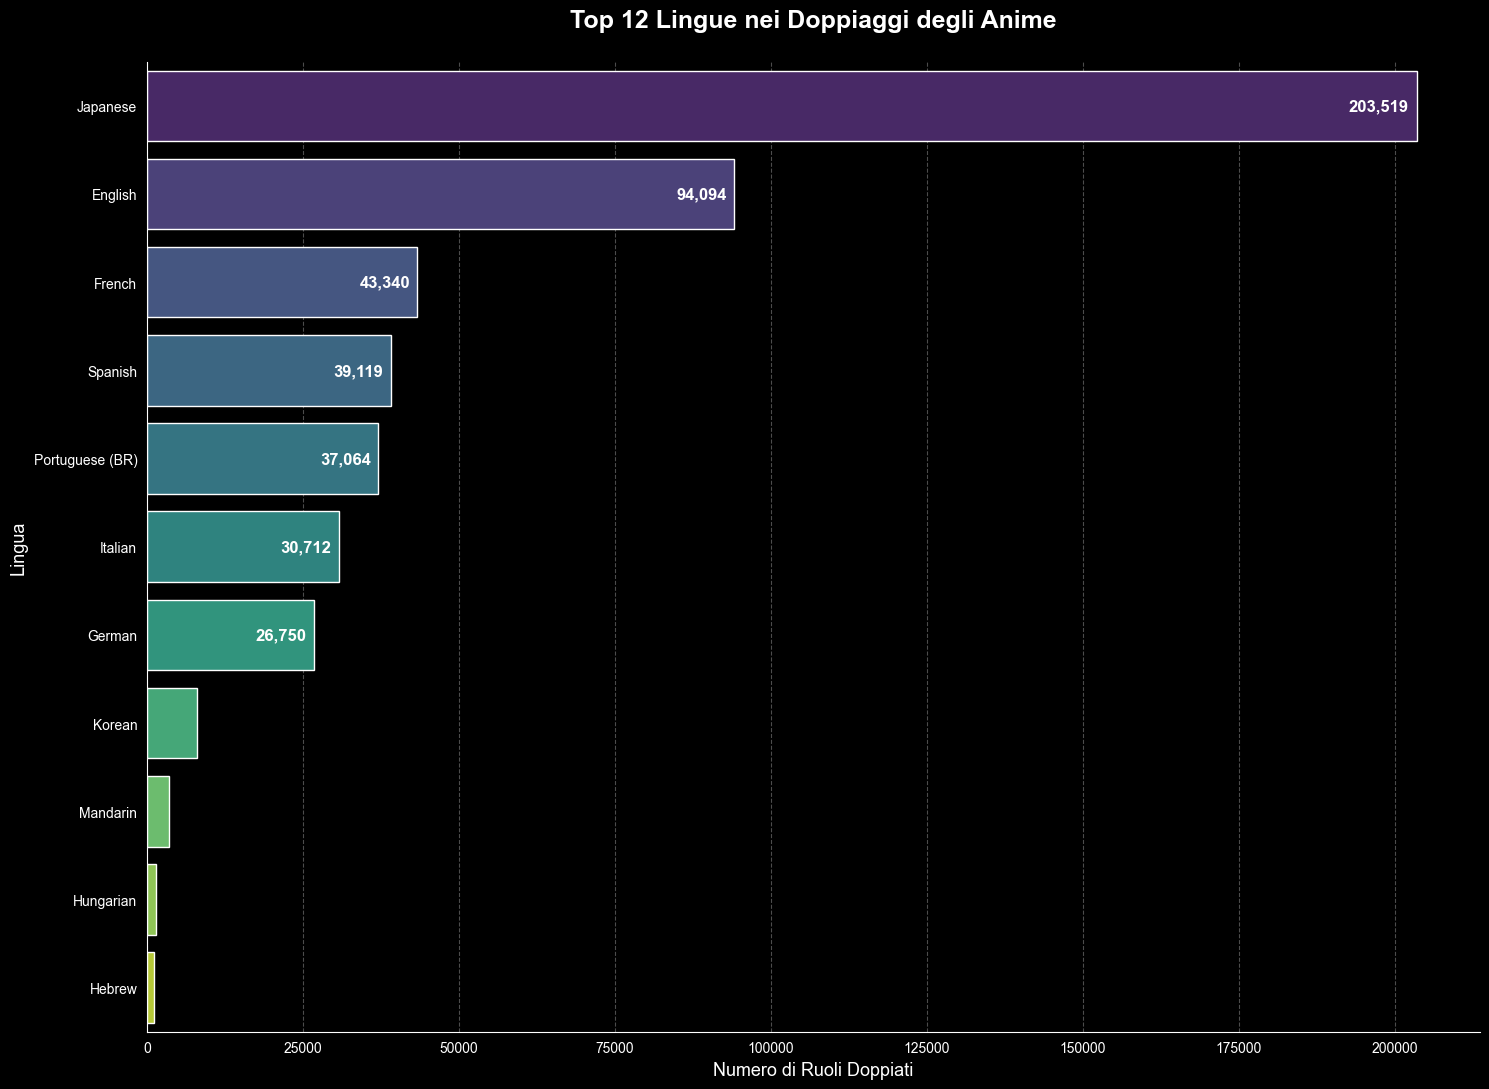

In [21]:
voice = df_person_voice_works.copy()
# Preparazione dati
lang_stats = voice.groupby('language').agg(total_roles=('character_mal_id', 'count')).sort_values('total_roles', ascending=False)
# Top 12 lingue
top12 = lang_stats.head(12).reset_index()
plt.figure(figsize=(15, 11))

ax = sns.barplot(data=top12,y='language',x='total_roles',palette='viridis')
plt.title('Top 12 Lingue nei Doppiaggi degli Anime',fontsize=18,fontweight='bold',pad=25)
plt.xlabel('Numero di Ruoli Doppiati', fontsize=13)
plt.ylabel('Lingua', fontsize=13)

for i, row in enumerate(top12.itertuples()):

    if row.total_roles > 10000:
        # Per barre lunghe
        ax.text(x = row.total_roles - 1200,y = i, s = f"{row.total_roles:,}",
            va = 'center',ha = 'right',fontsize = 12,color = 'white',fontweight = 'bold'
        )
    else:
        # Per barre corte
        ax.text(x = row.total_roles + 800,y = i,s = f"{row.total_roles:,}",
            va = 'center',ha = 'left',fontsize = 12,color = 'black',fontweight = 'bold'
        )

# Stile pulito
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

Le lingue più presenti nel doppiaggio mostrano la dimensione internazionale degli anime.
Ogni lingua rappresenta un possibile pubblico: l’anime non resta legato al contesto di origine, ma viene adattato, tradotto e reso accessibile a fan di paesi e culture diverse.

## 7. Community anime nel mondo

Gli anime non crescono soltanto come produzione: crescono anche attraverso le persone che li guardano, li commentano, li valutano e li inseriscono nelle proprie liste.
Dopo aver seguito titoli, personaggi e doppiatori, la storia si sposta quindi sulla community: dove si concentra e come si è sviluppata nel tempo.

## Dov'è concentrata la community anime?

In [22]:
profiles = df_profiles.copy()

# estrazione del paese
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()

profiles["country"] = (
    profiles["country"]
    .replace(utils.COUNTRY_FIX)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# conversione in ISO3
profiles["iso3"] = profiles["country"].apply(utils.to_iso3)

# controlli
u_total = profiles["username"].nunique()
u_loc = profiles.loc[profiles["location"].notna(), "username"].nunique()
u_iso = profiles.loc[profiles["iso3"].notna(), "username"].nunique()

print(f"Unique users: {u_total:,}")
print(f"Users with location: {u_loc:,} ({u_loc/u_total:.1%})")
print(f"Users mapped to ISO3: {u_iso:,} ({u_iso/u_total:.1%} of total)")
print(f"Coverage among users with location: {u_iso/u_loc:.1%}")

# conteggio utenti unici per paese
country_counts = (
    profiles.dropna(subset=["iso3"])
    .groupby("iso3")["username"]
    .nunique()
    .reset_index(name="n_users")
)

country_counts["log_users"] = np.log10(country_counts["n_users"] + 1)

# mappa
fig = px.choropleth(
    country_counts,
    locations="iso3",
    color="log_users",
    hover_data={"n_users": True, "log_users": ":.2f"},
    title="Dov'è concentrata la community anime?",
    color_continuous_scale=px.colors.sequential.Plasma
)

fig.update_layout(
    width=1000,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)

fig.update_coloraxes(
    colorbar_title=dict(text="log10(users)", font=dict(color="black")),
    colorbar_tickfont=dict(color="black")
)

fig.update_geos(
    showland=True,
    landcolor="lightgrey",
    showocean=True,
    oceancolor="#e6f2ff"
)

fig.show()

La mappa allarga lo sguardo e mostra la presenza della community su scala mondiale.
Questo grafico  fa capire bene quanto gli anime siano usciti dal loro contesto di origine e siano diventati un interesse condiviso a livello internazionale. Non si parla più di un fenomeno solo giapponese, ma di una community molto ampia e diffusa.


> **Nota sui dati:** i paesi sono stati ricavati dal campo **location** dei profili utente, normalizzato e convertito in codice ISO3. Su 337154 utenti unici, tutti presentavano una localizzazione valida e sono stati mappati correttamente (copertura 100%). La mappa mostra il numero di utenti unici per paese su scala logaritmica log10(user + 1), così da rendere leggibili anche paesi con meno utenti


## I principali poli geografici della community anime

In [23]:
top6_counts = (
    profiles.groupby("country")["username"].nunique().sort_values(ascending=False).head(6).reset_index(name="n_users")
)
fig = px.bar( top6_counts, x="country", y="n_users", text="n_users", title="I principali poli geografici della community anime", labels={"country": "Country", "n_users": "Unique users"}
)
fig.update_traces(textposition="outside")
fig.update_layout(
    width=900, height=500
)
fig.update_yaxes(tickformat=".2s")
fig.update_xaxes(categoryorder="total descending")

fig.show()

Alcuni paesi concentrano una parte molto ampia della community. Questo grafico mette in evidenza i principali poli geografici degli utenti, rendendo immediatamente visibili le aree più rappresentate.

Dopo aver individuato i paesi più rappresentati, possiamo osservare come questa community sia cresciuta nel tempo, per capire se l’interesse verso gli anime si è sviluppato in modo costante o se ci sono stati momenti di maggiore espansione.

## Crescita nella community nel tempo

In [24]:
profiles = df_profiles.copy()
profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()

profiles = profiles.dropna(subset=["joined_year", "country"])
top_countries = (
    profiles.groupby("country")["username"].nunique().sort_values(ascending=False).head(6).index
)

trend = (
    profiles.loc[
        profiles["country"].isin(top_countries) & profiles["joined_year"].between(2005, 2024)
    ].groupby(["joined_year", "country"])["username"].nunique().reset_index(name="n_users")
)

fig = px.line(
    trend, x="joined_year", y="n_users", color="country", markers=True, title="La crescita nel tempo dei principlai poli geografici",
    labels={
        "joined_year": "Year", "n_users": "New Users", "country": "Country"
    }
)
fig.update_layout(
    width=900, height=500
)

fig.show()

Il grafico mostra l’evoluzione nel tempo dei nuovi utenti nei principali paesi della community anime. Si nota una crescita progressiva soprattutto per Giappone e Stati Uniti, che restano i due paesi più forti anche nel corso degli anni.
A parer mio questo grafico è utile perché fa capire che la community anime non è nata tutta insieme, ma si è costruita nel tempo. È interessante vedere come alcuni paesi crescano in modo molto più rapido rispetto ad altri.

Le community nazionali non crescono tutte allo stesso ritmo. Alcune aumentano prima, altre più tardi, altre ancora mostrano fasi di crescita più concentrate.
Questo grafico trasforma la geografia in una storia temporale: non mostra solo dove sono gli utenti, ma quando quelle community diventano più visibili.
Notiamo anche un forte calo da parte di tutti i Paesi principali, nel 2022, che a mio parere potrebbe essere legato al ritorno alla normalità dopo il periodo pandemico, quando molte persone avevano più tempo per scoprire contenuti online. 

## Crescita della community nel tempo a livello globale

In [25]:
df = df_profiles.copy()
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year
users_per_year = (
    df.dropna(subset=["joined_year"]).groupby("joined_year")["username"].nunique().reset_index(name="new_users")
)
users_per_year["joined_year"] = users_per_year["joined_year"].astype(int)
users_per_year = users_per_year[users_per_year["joined_year"].between(2005, 2024)]
fig = px.line(
    users_per_year, x="joined_year", y="new_users", markers=True, title="Nuovi utenti registrati per anno",
    labels={
        "joined_year": "Anno", "new_users": "Nuovi utenti"
    }
)
fig.add_vrect(x0=2008, x1=2009, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_vrect(x0=2020, x1=2022, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_annotation(
    x=2008.5, y=users_per_year["new_users"].max() * 0.95, text="Crisi finanziaria", showarrow=False
)
fig.add_annotation(
    x=2021, y=users_per_year["new_users"].max() * 0.95, text="Pandemia COVID-19", showarrow=False
)
fig.update_layout(
    width=850, height=450
)
fig.show()

La crescita degli utenti registrati mostra come la community online si sia allargata nel tempo.

Secondo me questo grafico è interessante perché mostra quanto la community anime sia cresciuta insieme all’uso delle piattaforme online. Il picco durante il periodo
pandemico può essere letto come un momento in cui molte persone avevano più tempo per scoprire nuovi contenuti e iscriversi a community digitali.


> **Nota sui dati:** 13.848 utenti con anno di iscrizione fuori dall’intervallo 2005–2024 e 1.676 utenti con data non leggibile sono stati esclusi dal grafico. La curva rappresenta quindi il 95,4% degli utenti totali.

Dopo aver osservato la crescita complessiva della community, possiamo guardare più da vicino chi compone questa community, analizzando alcune caratteristiche dichiarate dagli utenti nei loro profili.

## Genere più diffuso nella community anime

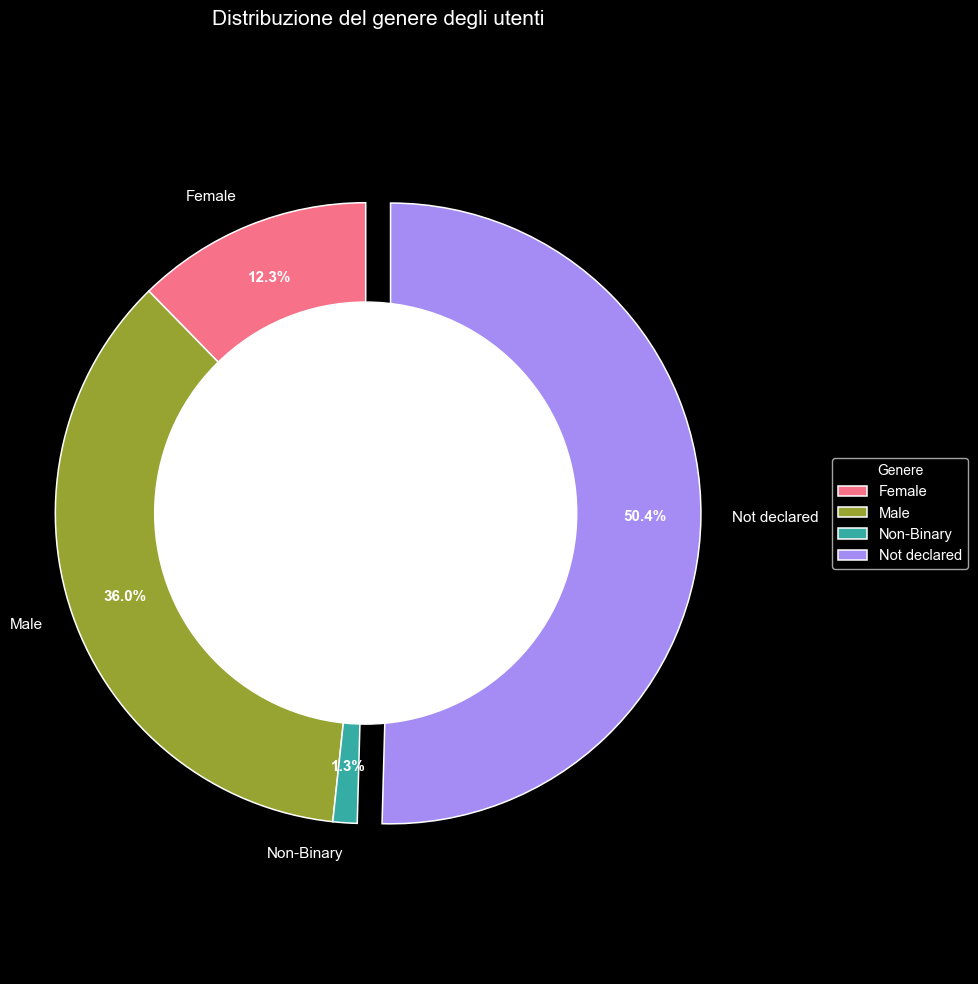

In [26]:
# preparazione dati
profiles_gender = profiles.copy()

profiles_gender["gender"] = (
    profiles_gender["gender"]
    .fillna("Not declared")
    .replace("", "Not declared")
    .str.strip()
)

gender_counts = (
    profiles_gender["gender"]
    .value_counts()
    .reindex(["Female", "Male", "Non-Binary", "Not declared"], fill_value=0)
    .rename_axis("gender")
    .reset_index(name="count")
)

gender_counts["percentage"] = (
    gender_counts["count"] / gender_counts["count"].sum() * 100
).round(1)

gender_plot = gender_counts[gender_counts["count"] > 0].copy()
pie_data = gender_plot.set_index("gender")["count"]

# grafico
plt.figure(figsize=(10, 10))
colors = sns.color_palette("husl", len(pie_data))

explode = [0.08 if gender == pie_data.idxmax() else 0 for gender in pie_data.index]

wedges, texts, autotexts = plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={"edgecolor": "white", "linewidth": 1.1},
    textprops={"fontsize": 11}
)

for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontweight("bold")

plt.title("Distribuzione del genere degli utenti", fontsize=15, pad=20)

centre_circle = plt.Circle((0, 0), 0.68, fc="white")
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.legend(
    pie_data.index,
    title="Genere",
    loc="center left",
    bbox_to_anchor=(1.15, 0.5),
    fontsize=10.5
)

plt.axis("equal")
plt.tight_layout()
plt.show()

Il genere dichiarato offre una prima lettura per capire come è composta la community anime, ma va interpretato con cautela: non tutti gli utenti scelgono di condividere questa informazione.
Per questo il grafico racconta soprattutto ciò che gli utenti dichiarano nella piattaforma, più che una fotografia definitiva dell’intero pubblico anime.


> **Nota sui dati:** i valori mancanti o vuoti nella colonna gender sono stati raggruppati nella categoria Not declared. Il grafico include anche la categoria Non-Binary e considera tutti i 335.478 profili utente presenti. Le percentuali descrivono quindi il genere indicato dagli utenti nei profili, includendo anche chi non ha fornito questa informazione.

## 8. PERSONE E RUOLI NELL'INDUSTRIA ANIME

Dietro ogni anime non ci sono solo personaggi e doppiatori, ma anche una rete più ampia di persone: autori, registi, musicisti, produttori e molte altre figure professionali.

## Da quali paesi provengono le persone che lavorano nell'industria anime

In [27]:
country_counts = df_person_details.copy()
country_counts["country"] = (
    country_counts["relevant_location"]
    .astype("string")
    .str.split(",")
    .str[-1]
    .str.strip()
)
country_counts["country"] = country_counts["country"].replace(utils.COUNTRY_FIX)
country_counts = (
    country_counts.groupby("country")["person_mal_id"]
    .nunique()
    .reset_index(name="n_people")
)
country_counts["iso3"] = country_counts["country"].apply(utils.to_iso3)
present_df = country_counts.dropna(subset=["iso3"]).copy()

fig = px.choropleth(
    present_df,
    locations="iso3",
    color="n_people",
    hover_name="country",
    title="Da quali paesi provengono i produttori degli anime?",
    color_continuous_scale=["#dff5ef", "#7fd6c2"]
)

fig.update_layout(
    width=1000,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)

fig.update_geos(
    showland=True,
    landcolor="white",
    showcountries=True,
    countrycolor="lightgrey",
    showocean=True,
    oceancolor="#f5f7fb",
    showframe=False
)

fig.show()

Il grafico mostra da quali paesi provengono coloro che lavorano nell'industria anime. La mappa evidenzia una forte presenza del Giappone, come prevedibile, ma mostra anche contributi da altri paesi, soprattutto Stati Uniti ed Europa. Questo permette di vedere l’industria anime non solo dal lato del pubblico, ma anche dal lato delle persone che partecipano alla produzione.

Questo passaggio è interessante perché permette di distinguere la diffusione del pubblico dalla distribuzione delle figure professionali: la community può essere globale, ma la produzione segue logiche e concentrazioni diverse.


> **Nota dati:** I paesi sono stati estratti da **relevation_location** e convertiti in ISO3. La mappa rappresenta 76.594 professionisti distribuiti in 12 paesi, con compertura completa.

Oltre alla provenienza geografica, possiamo osservare anche quali generazioni hanno contribuito alla costruzione dell’industria anime.

## Distribuzione Generazionale delle persone che lavorano nell'industria anime

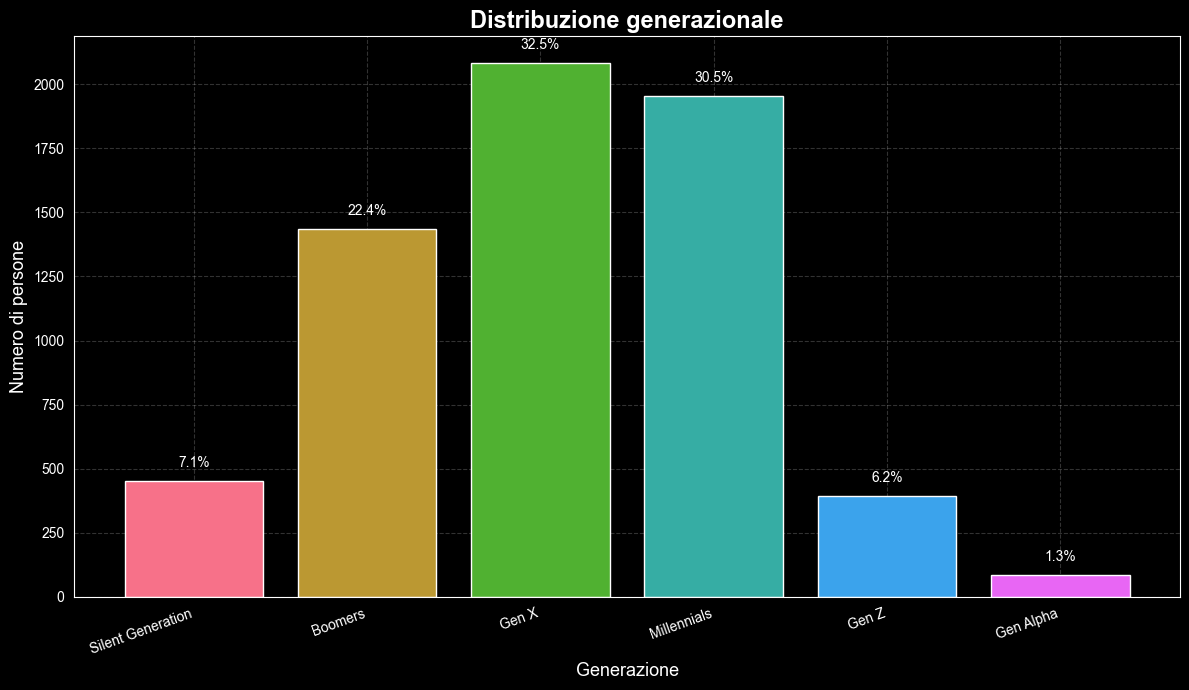

In [28]:
# preparazione dati
staff = (
    df_person_anime_works[["person_mal_id"]]
    .drop_duplicates()
    .merge(
        df_person_details[["person_mal_id", "birthday"]],
        on="person_mal_id",
        how="left"
    )
)

staff["birth_year"] = pd.to_datetime(
    staff["birthday"], errors="coerce",  utc=True
).dt.year

staff.loc[~staff["birth_year"].between(1900, 2024), "birth_year"] = pd.NA

labels = [
    "Silent Generation", "Boomers", "Gen X", "Millennials", "Gen Z", "Gen Alpha"
]

staff["generation"] = pd.cut(
    staff["birth_year"],
    bins=[-np.inf, 1945, 1964, 1980, 1996, 2012, 2024],
    labels=labels
)

gen_counts = (
    staff["generation"]
    .value_counts()
    .reindex(labels, fill_value=0)
    .rename_axis("generation")
    .reset_index(name="count")
)

gen_counts["share"] = (
    gen_counts["count"] / gen_counts["count"].sum() * 100
).round(1)

# grafico
plt.figure(figsize=(12, 7))
colors = sns.color_palette("husl", n_colors=len(gen_counts))

bars = plt.bar(
    gen_counts["generation"],
    gen_counts["count"],
    color=colors
)

for bar, share in zip(bars, gen_counts["share"]):
    height = bar.get_height()
    plt.text(
    bar.get_x() + bar.get_width()/2.,
    height + gen_counts["count"].max() * 0.02,
    f'{share}%',
    ha='center',
    va='bottom',
    fontsize=10
)

plt.xlabel("Generazione", fontsize=13)
plt.ylabel("Numero di persone", fontsize=13)
plt.title("Distribuzione generazionale", fontsize=17, fontweight='bold')

plt.xticks(rotation=20, ha='right')
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

Il grafico mostra la distribuzione generazionale delle persone presenti nei credits degli anime. Le generazioni più rappresentate sono Gen X e Millennials, seguite dai Boomers, mentre Gen Z e Gen Alpha risultano ancora meno presenti. Questo suggerisce che una parte importante dell’industria anime è composta da professionisti con esperienza, spesso attivi da molti anni nel settore.

Secondo me questo grafico è interessante perché fa vedere che dietro agli anime ci sono generazioni diverse che hanno contribuito alla crescita dell’industria. Il peso forte di Gen X e Millennials può indicare che molti professionisti oggi centrali nel settore appartengono a generazioni che hanno vissuto sia l’anime più tradizionale sia la sua espansione internazionale.


> **Nota sui dati:** su 26.236 persone presenti nei credits anime, solo 6.409 avevano un anno di nascita valido tra 1900 e 2024. Il grafico rappresenta quindi il 24,4% del totale; le altre persone sono state escluse per assenza o non validità della data di nascita.

## Ruoli più frequenti e notorietà nell'industria anime

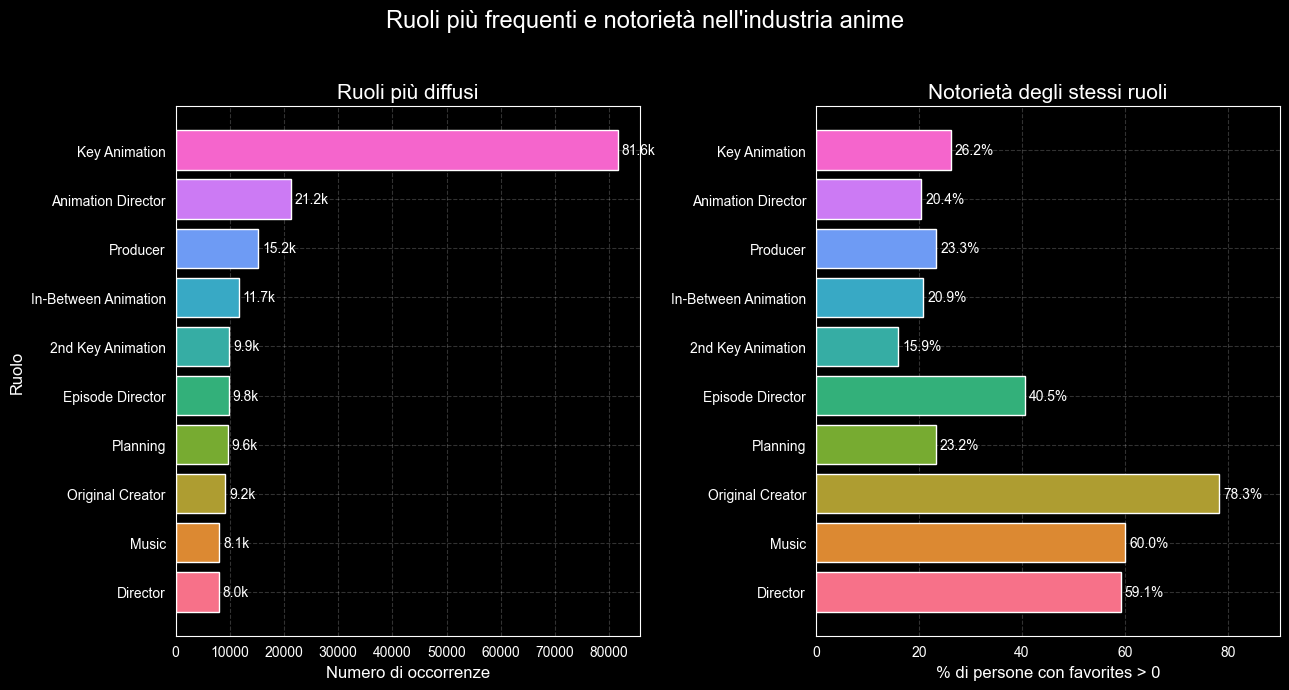

In [29]:
top10 = df_person_anime_works["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip().value_counts().head(10).rename_axis("role").reset_index(name="occurrences")

role_people = df_person_anime_works.loc[
    df_person_anime_works["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip().isin(top10["role"]), ["person_mal_id", "position"]
].copy()
role_people["role"] = role_people["position"].str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True).str.strip()
role_people = role_people.drop_duplicates(subset=["person_mal_id", "role"])
role_people = role_people.merge(df_person_details[["person_mal_id", "favorites"]], on="person_mal_id", how="left")
fav_stats = role_people.groupby("role")["favorites"].agg(share_nonzero=lambda x: (x.fillna(0) > 0).mean() * 100).reset_index()

top10 = top10.merge(fav_stats, on="role", how="left").sort_values("occurrences", ascending=True)
colors = sns.color_palette("husl", len(top10))
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
bars1 = ax[0].barh(top10["role"], top10["occurrences"], color=colors)
bars2 = ax[1].barh(top10["role"], top10["share_nonzero"], color=colors)
ax[0].set_title("Ruoli più diffusi", fontsize=15)
ax[1].set_title("Notorietà degli stessi ruoli", fontsize=15)
ax[0].set_xlabel("Numero di occorrenze", fontsize=12)
ax[1].set_xlabel("% di persone con favorites > 0", fontsize=12)
ax[0].set_ylabel("Ruolo", fontsize=12)
labels_occ = (top10["occurrences"] / 1000).round(1).astype(str) + "k"
labels_fav = top10["share_nonzero"].round(1).astype(str) + "%"
ax[0].bar_label(bars1, labels=labels_occ, padding=3, fontsize=10)
ax[0].grid(True, alpha=0.2, linestyle='--')
ax[1].bar_label(bars2, labels=labels_fav, padding=3, fontsize=10)
ax[1].set_xlim(0, top10["share_nonzero"].max() * 1.15)
ax[1].grid(True, alpha=0.2, linestyle='--')

fig.suptitle("Ruoli più frequenti e notorietà nell'industria anime", fontsize=17)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Il grafico confronta i ruoli più frequenti nei credits anime con la loro notorietà, misurata come percentuale di persone con almeno un favourite. A sinistra si vede che ruoli tecnici come Key Animation sono molto presenti, mentre a destra emerge che ruoli come Original Creator e Director tendono ad avere una notorietà più alta. Questo mostra una differenza interessante tra chi compare più spesso nella produzione e chi viene maggiormente riconosciuto dal pubblico.

Personalmente penso che questo grafico è uno dei più interessanti della sezione industria, perché fa capire che quantità e riconoscibilità non coincidono sempre. Alcuni ruoli sono fondamentali e molto frequenti, ma meno visibili per i fan; altri invece compaiono meno spesso, ma sono più associati all’identità dell’opera e quindi ricevono più attenzione.

## Top 15 professionisti per nomi alternativi

Un professionista che lavora in molti paesi accumula nomi alternativi: traslitterazioni, pseudonimi, nomi d'arte in lingue diverse. Il numero di nomi alternativi è un indicatore della portata internazionale di una figura nell'industria anime.

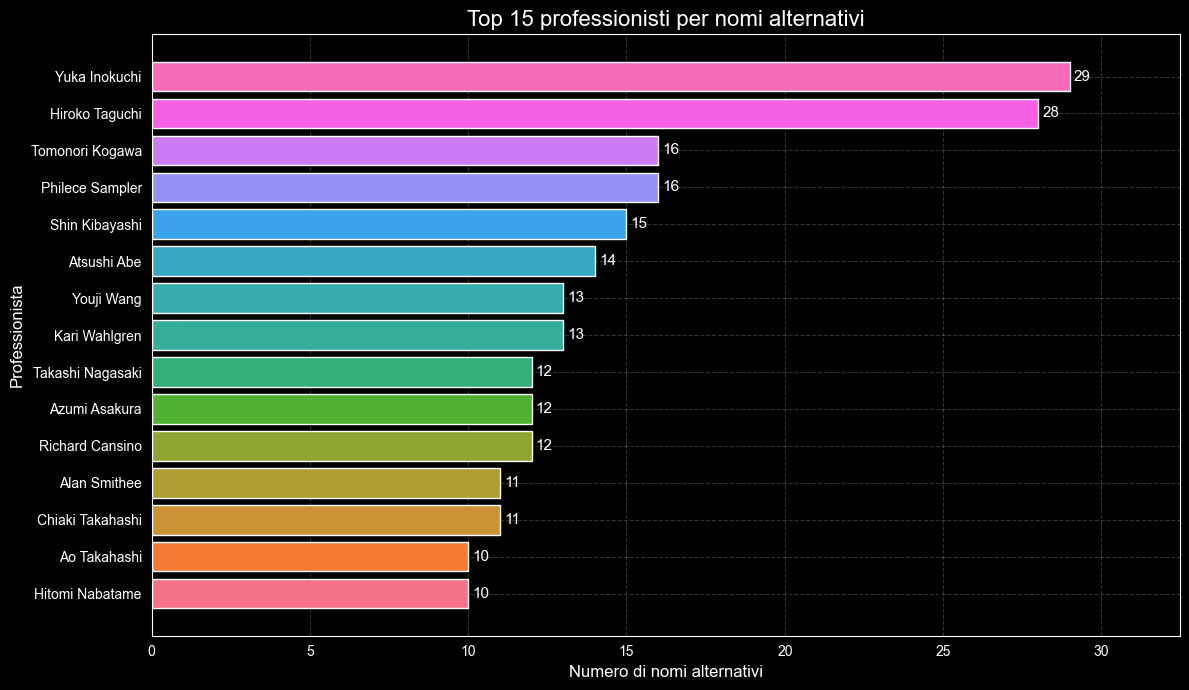

In [30]:
alt_names = df_person_alternate_names.copy()
person_details = df_person_details.copy()

alt_name_counts = (alt_names.groupby("person_mal_id").size().reset_index(name="alt_name_count"))

top_alt = (
    pd.merge(
        alt_name_counts.nlargest(15, "alt_name_count"),
        person_details[["person_mal_id", "name", "favorites"]],
        on="person_mal_id", how="left"
    )
    .sort_values("alt_name_count", ascending=True)
)

palette = sns.color_palette("husl", len(top_alt))
fig, ax = plt.subplots(figsize=(12, 7))


bars = ax.barh(top_alt["name"], top_alt["alt_name_count"], color=palette)
ax.set_title("Top 15 professionisti per nomi alternativi", fontsize=16)
ax.set_xlabel("Numero di nomi alternativi", fontsize=12)
ax.set_ylabel("Professionista", fontsize=12)
ax.bar_label(bars, padding=3, fontsize=11)
ax.set_xlim(0, top_alt["alt_name_count"].max() * 1.12)
plt.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()

I professionisti con più nomi alternativi sono spesso figure di rilievo internazionale, conosciute sotto forme diverse del loro nome in paesi e mercati differenti. Ogni nome alternativo rappresenta un mercato raggiunto, una community che ha adottato quel professionista nel proprio contesto culturale, riflettendo la circolazione globale dell'industria anime.

Dopo aver analizzato le persone che lavorano dietro agli anime, possiamo tornare al lato degli utenti e osservare come la community organizza la propria esperienza di visione: cosa guarda, cosa completa, cosa abbandona e cosa mette in lista per il futuro.

## 9. COME SONO SEGUITI GLI ANIME

Guardare anime non significa soltanto scegliere un titolo e valutarlo. Gli utenti costruiscono vere e proprie liste personali: anime completati, in corso, messi in pausa, abbandonati o pianificati per il futuro.

### Tra completati, abbandonati e pianificati: lo stato di visione

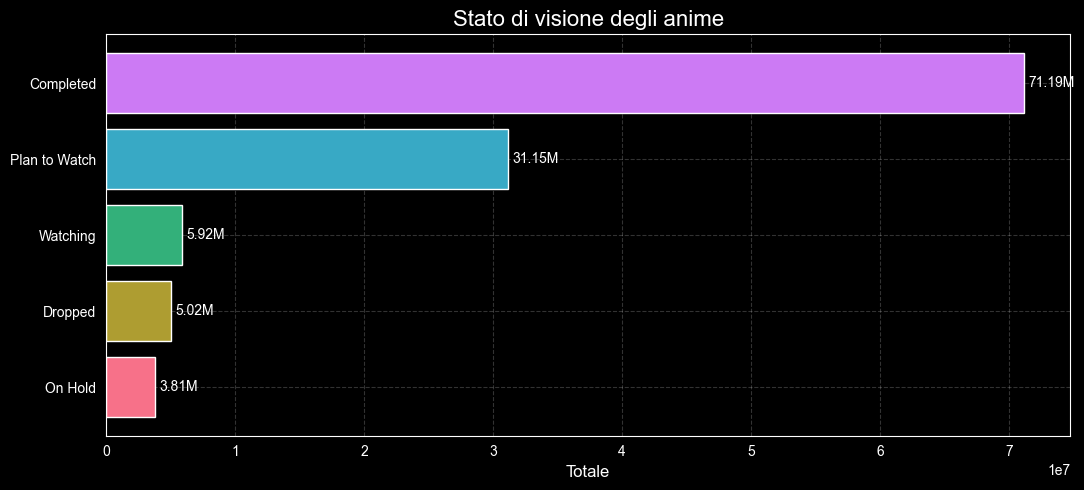

In [31]:
profiles = df_profiles.copy()

cols = utils.WATCH_STATUS_COLS
profiles[cols] = profiles[cols].fillna(0)

status_totals = profiles[cols].sum().rename_axis("status").reset_index(name="total")
status_totals["status"] = status_totals["status"].replace(utils.WATCH_STATUS_LABELS)
status_totals = status_totals.sort_values("total")
palette = sns.color_palette("husl", len(status_totals))
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    status_totals["status"], status_totals["total"], color=palette)

ax.set_title("Stato di visione degli anime", fontsize=16)
ax.set_xlabel("Totale", fontsize=12)
ax.set_ylabel("")

labels_bar = (status_totals["total"] / 1000000).round(2).astype(str) + "M"
ax.bar_label(bars, labels=labels_bar, padding=3, fontsize=10)
plt.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()

Il grafico mostra come gli utenti distribuiscono gli anime nelle proprie liste personali: completati, pianificati, in visione, abbandonati o messi in pausa. La categoria Completed è nettamente la più alta, seguita da Plan to Watch, indicando che gli utenti usano la piattaforma sia per registrare ciò che hanno già visto sia per organizzare ciò che vogliono guardare in futuro.

Questo grafico non mostra solo la popolarità degli anime, ma anche il modo in cui gli utenti gestiscono il proprio rapporto con un catalogo enorme: alcuni titoli vengono completati, altri restano in lista, altri ancora vengono abbandonati o messi in pausa.

## Come cambia lo stato nel tempo?

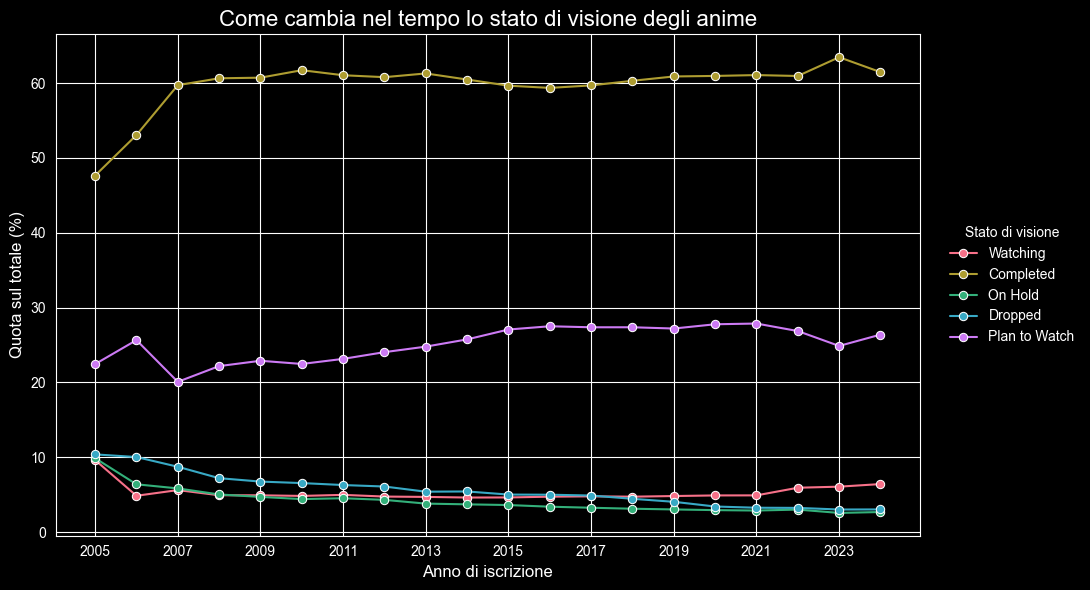

In [32]:
profiles = df_profiles.copy()

profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year

cols = utils.WATCH_STATUS_COLS
profiles[cols] = profiles[cols].fillna(0)

profiles = profiles.dropna(subset=["joined_year"])
profiles["joined_year"] = profiles["joined_year"].astype(int)
profiles = profiles[profiles["joined_year"].between(2005, 2024)]

status_palette = dict(zip(utils.WATCH_STATUS_ORDER, sns.color_palette("husl", len(utils.WATCH_STATUS_ORDER))))
cohort_totals = profiles.groupby("joined_year")[cols].sum().reset_index()
den = cohort_totals[cols].sum(axis=1)
cohort_pct = cohort_totals.loc[den > 0].copy()
cohort_pct[cols] = cohort_pct[cols].div(cohort_pct[cols].sum(axis=1), axis=0) * 100

cohort_long = cohort_pct.melt(
    id_vars="joined_year", value_vars=cols, var_name="status", value_name="share"
)

cohort_long["status"] = cohort_long["status"].replace(utils.WATCH_STATUS_LABELS)

fig, ax = plt.subplots(figsize=(11, 6))


sns.lineplot(
    data=cohort_long, x="joined_year", y="share", hue="status", palette=status_palette, marker="o", ax=ax
)

ax.set_title("Come cambia nel tempo lo stato di visione degli anime", fontsize=16)
ax.set_xlabel("Anno di iscrizione", fontsize=12)
ax.set_ylabel("Quota sul totale (%)", fontsize=12)

ax.set_xticks(cohort_pct["joined_year"][::2])
ax.set_xticklabels(cohort_pct["joined_year"][::2].astype(int))

ax.legend(
    title="Stato di visione", loc="center left", bbox_to_anchor=(1.02, 0.5) , frameon=False
)
plt.tight_layout()
plt.show()

Questo grafico mostra come cambia nel tempo la composizione degli stati di visione tra gli utenti registrati in anni diversi.

L’aspetto interessante non è solo quanti anime vengono guardati, ma come cambia il modo di gestirli: completare, pianificare o abbandonare un titolo diventano segnali del rapporto tra utenti e catalogo.
Notiamo che l’abbandono rimane relativamente basso rispetto ai titoli completati o pianificati.

In questo modo, la community non appare solo come un insieme di utenti, ma come un pubblico attivo che guarda, valuta, organizza e costruisce nel tempo il proprio rapporto con gli anime.


>**Nota sui dati:** Si considerano gli utenti con anno di iscrizione tra 2005-2024, per un totale di 20 anni. Sono stati esclusi 13.850 utenti fuori intervallo e 1.676 utenti con data non leggibile. Il grafico rappresenta quindi 321.628 utenti, pari al 95,4% del totale. I valori mancanti sono trattati come 0 e le percentuali sono calcolate sul totale degli stati di visione di ciascun anno.

## Completamento e abbandono: cosa rivelano le statistiche per anime

Oltre alle preferenze globali della community, il dataset fornisce statistiche dettagliate per ciascun anime: quanti utenti li hanno completati, quanti li hanno abbandonati. Questi dati raccontano il rapporto reale tra gli utenti e i singoli titoli, andando oltre la semplice popolarità.

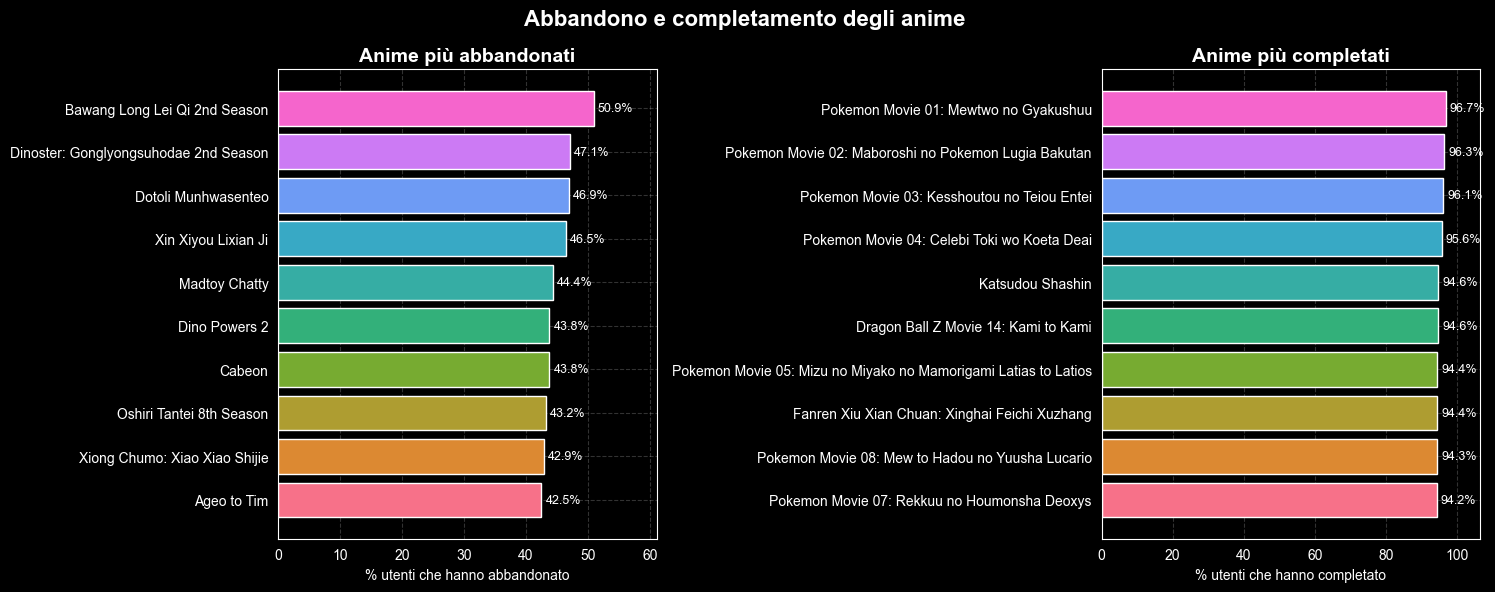

In [33]:
stats = df_stats.copy()
details = df_details.copy()

# considero solo anime con abbastanza utenti
stats = stats[stats["total"] >= 200].copy()
stats["completion_rate"] = stats["completed"] / stats["total"] * 100
stats["drop_rate"] = stats["dropped"] / stats["total"] * 100

merged_stats = stats.merge(details[["mal_id", "title"]], on="mal_id", how="inner")

most_dropped = (
    merged_stats.nlargest(10, "drop_rate")
    [["title", "drop_rate"]]
    .sort_values("drop_rate")
)

most_completed = (
    merged_stats[merged_stats["total"] >= 500]
    .nlargest(10, "completion_rate")
    [["title", "completion_rate"]]
    .sort_values("completion_rate")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors1 = sns.color_palette("husl", len(most_dropped))
colors2 = sns.color_palette("husl", len(most_completed))

bars1 = axes[0].barh(most_dropped["title"], most_dropped["drop_rate"], color=colors1)
axes[0].bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=9)
axes[0].set_title("Anime più abbandonati", fontsize=14, fontweight="bold")
axes[0].set_xlabel("% utenti che hanno abbandonato")
axes[0].set_ylabel("")
axes[0].grid(True, alpha=0.2, linestyle='--')
axes[0].set_xlim(0, most_dropped["drop_rate"].max() * 1.2)

bars2 = axes[1].barh(most_completed["title"], most_completed["completion_rate"], color=colors2)
axes[1].bar_label(bars2, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].set_title("Anime più completati", fontsize=14, fontweight="bold")
axes[1].set_xlabel("% utenti che hanno completato")
axes[1].set_ylabel("")
axes[1].grid(True, alpha=0.2, linestyle='--')
axes[1].set_xlim(0, most_completed["completion_rate"].max() * 1.1)


plt.suptitle("Abbandono e completamento degli anime", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Il grafico confronta due comportamenti opposti degli utenti: da un lato gli anime con il tasso di abbandono più alto, dall’altro quelli con il tasso di completamento più elevato.
Per evitare risultati poco rappresentativi sono stati considerati solo anime con un numero minimo di utenti. Si nota che alcuni titoli hanno percentuali di abbandono molto elevate, mentre gli anime più completati superano quasi sempre il 90%, **suggerendo una forte differenza tra serie/film che gli utenti tendono a lasciare e serie/film che vengono seguite fino alla fine.**

Personalmente trovo interessante questo confronto perché mostra che la popolarità non racconta tutto: alcuni titoli riescono a trattenere molto bene gli utenti fino alla fine, mentre altri vengono iniziati ma poi abbandonati più spesso. Questo rende il completamento un indicatore utile per capire non solo quanto un anime attira attenzione, ma anche quanto riesce davvero a mantenerla.

## 10. IL PUBBLICO A CUI SI RIVOLGONO GLI ANIME

Ogni anime non racconta solo una storia: si rivolge anche a un certo tipo di pubblico.

Dopo aver osservato produzione, popolarità, community e comportamento degli utenti, l’ultimo passaggio riguarda il target previsto: per chi vengono pensati gli anime e come questa struttura cambia nel tempo.

### Distribuzione dei target demografici

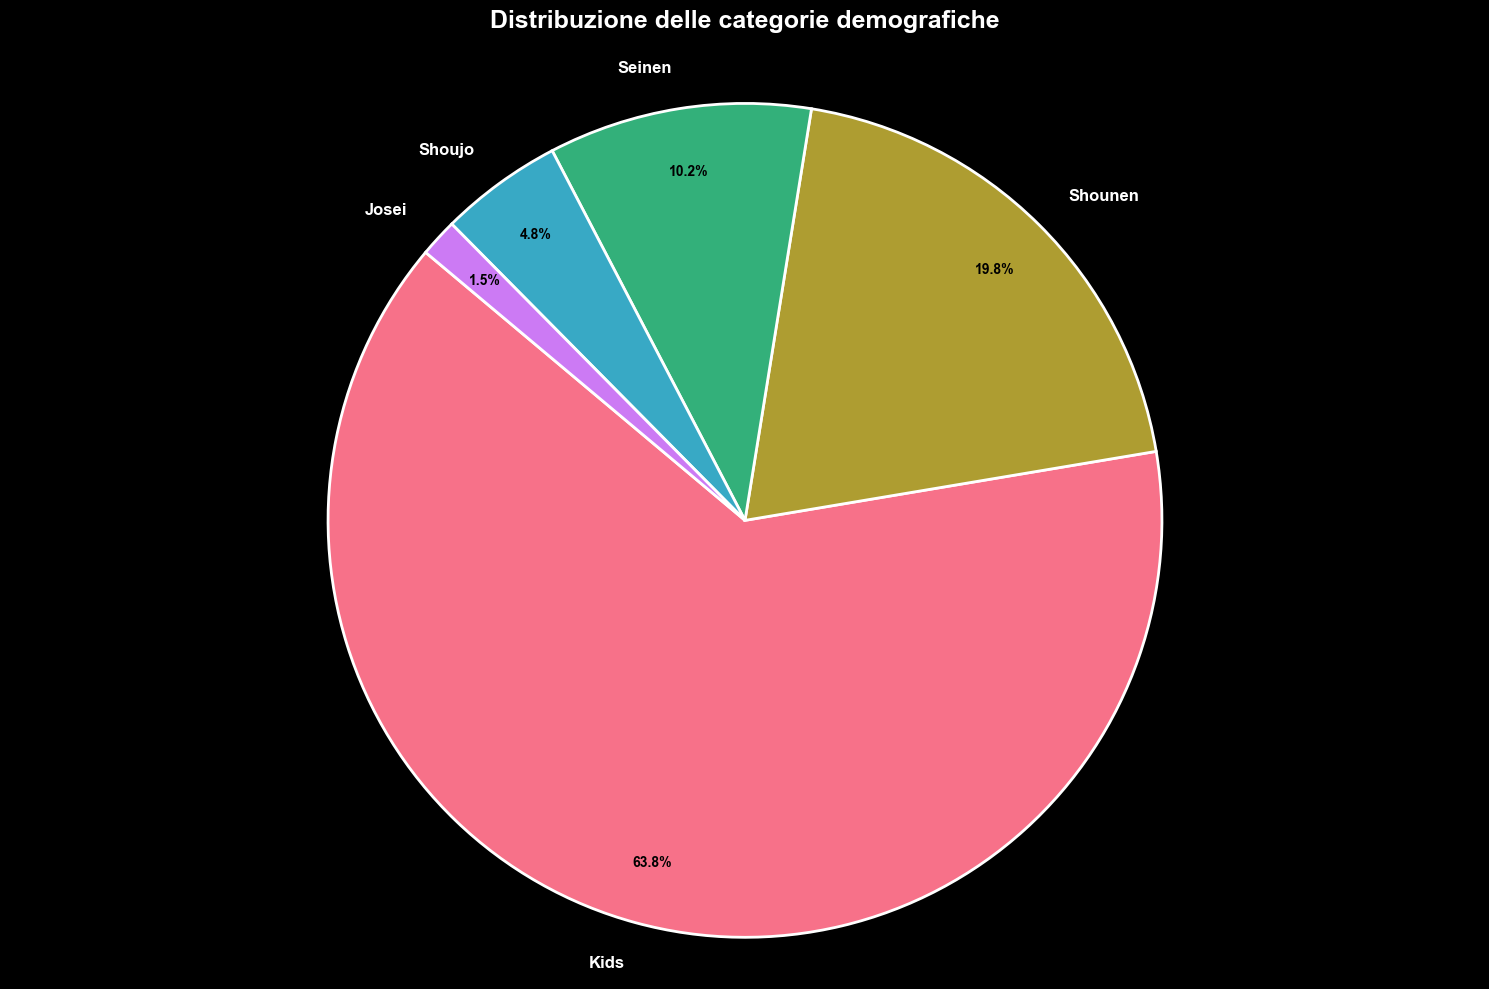

In [34]:
details_copy = df_details.copy()
details_copy = details_copy["demographics"].apply(eval).explode()

demographic_count = details_copy.value_counts()

colors = sns.color_palette("husl", len(demographic_count))

fig, ax = plt.subplots(figsize=(15, 10))


wedges, texts, autotexts = ax.pie(
    demographic_count.values, labels=demographic_count.index, autopct="%1.1f%%",  startangle=140, colors=colors, wedgeprops={"edgecolor": "white", "linewidth": 2}, pctdistance=0.85, textprops={"fontsize": 11}
)
plt.setp(autotexts, size=10, weight="bold", color="black")
plt.setp(texts, size=12, weight="bold")
ax.set_title("Distribuzione delle categorie demografiche", fontsize=18, pad=25, fontweight="bold")
plt.axis("equal")
plt.tight_layout()
plt.show()

Le categorie demografiche indicano il pubblico principale a cui l’anime è rivolto: Shounen = ragazzi adolescenti, Shoujo = ragazze adolescenti, Seinen = uomini giovani/adulti, Josei = donne giovani/adulte, Kids = bambini.

Il grafico mostra la distribuzione delle principali categorie demografiche associate agli anime. La categoria più presente è Shounen, seguita da Shoujo, Seinen, Josei e Kids. Questo indica che una parte molto ampia degli anime presenti nel dataset è pensata per un pubblico giovane maschile, anche se sono presenti categorie rivolte ad altri target.

Secondo me questo grafico è particolarmente interessante perchè mostra che gli anime non sono pensati per un pubblico unico. Anche se Shounen domina nettamente, il dataset contiene categorie diverse, quindi l’anime appare come un prodotto molto vario, capace di rivolgersi a fasce di età e interessi differenti.

## Come evolgono nel tempo?

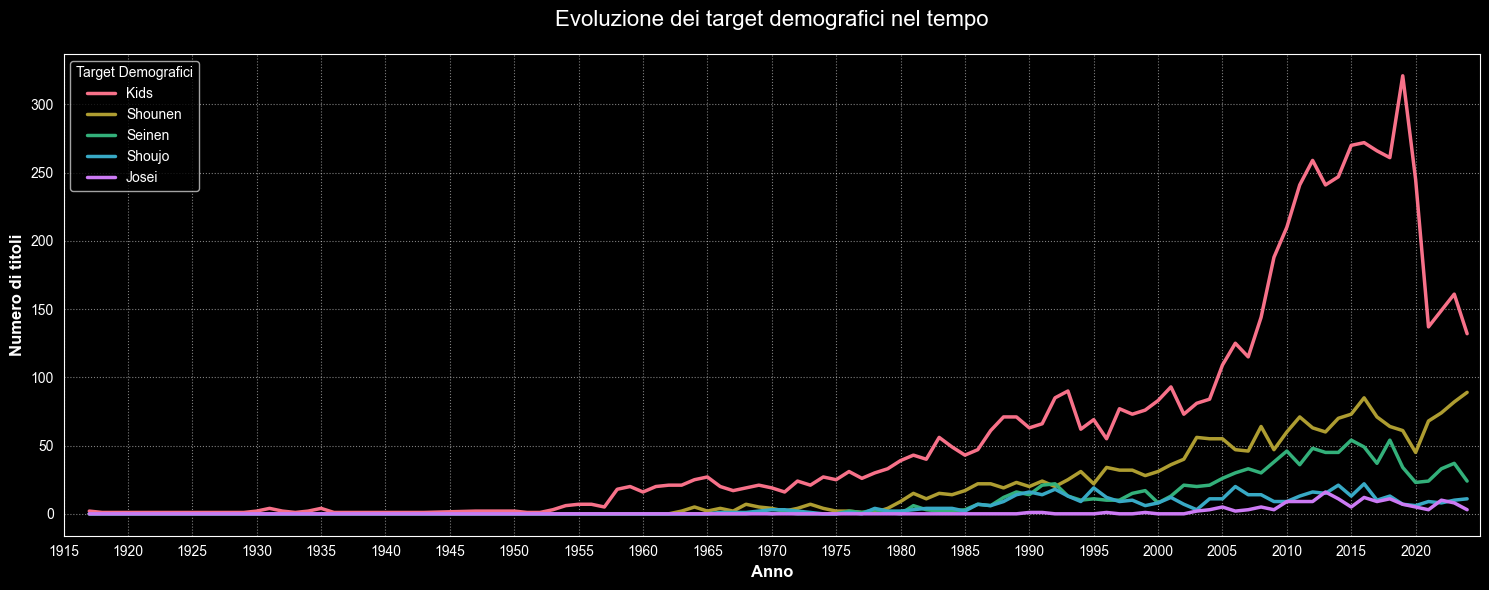

In [35]:
details_copy = df_details.copy()
details_copy = details_copy[details_copy['year'] < 2025].copy()
details_copy['demographics'] = details_copy['demographics'].apply(eval)
details_copy = details_copy.explode('demographics')
# conteggio per anno
counts = details_copy.groupby(['year', 'demographics']).size().unstack(fill_value=0).sort_index()
freq_order = details_copy['demographics'].value_counts().index
counts = counts[freq_order]
n_colors = len(counts.columns)
palette = sns.color_palette("husl", n_colors) #modificato perchè non compila, prima c'era palette = plt.cm.tab10.resampled(n)(range(n_colors))
# creazione grafico
plt.figure(figsize=(15,6))
plt.grid(linestyle=':', alpha=0.5)
counts.plot(kind='line', ax=plt.gca(), linewidth=2.5, color=palette)
# personalizzazione assi
plt.title(f'Evoluzione dei target demografici nel tempo', fontsize=16, pad=20)
plt.xlabel('Anno', fontsize=12, fontweight='bold')
plt.ylabel('Numero di titoli', fontsize=12, fontweight='bold')
plt.legend(title='Target Demografici', loc='upper left', frameon=True)
plt.xlim(1915, 2025)
plt.xticks(ticks=range(1915, 2024, 5))

plt.tight_layout()
plt.show()


Il grafico mostra come il numero di titoli per ciascuna categoria demografica sia cambiato nel corso di oltre un secolo. Le linee evidenziano un’evoluzione graduale fino agli anni ’70, seguita da un aumento più marcato in alcune categorie.
La crescita più evidente è quella della categoria Shounen, che a partire dagli anni ’70 accelera rapidamente fino a raggiungere un picco intorno al 2020. Questo andamento riflette l’enorme successo commerciale e culturale delle opere rivolte a un pubblico giovane maschile, spesso caratterizzate da azione, avventura e narrazioni seriali.
Le categorie Kids, Seinen, Shoujo e Josei mostrano invece una crescita più moderata, con incrementi costanti ma meno pronunciati. Questo suggerisce un’espansione complessiva dell’industria, ma con un’attenzione particolare verso i generi più popolari e redditizi.
Nel complesso, il grafico racconta una storia di diversificazione progressiva, ma anche di forte concentrazione su alcune fasce demografiche che hanno guidato l’evoluzione dell’animazione giapponese negli ultimi decenni.


---

## 11. CONCLUSIONE - GLI ANIME COME ECOSISTEMA CULTURALE E GLOBALE

Dalla crescita della produzione ai target demografici, il percorso mostra che gli anime funzionano come un ecosistema: opere, generi, utenti, personaggi, voci e professionisti si intrecciano nel tempo, costruendo un fenomeno culturale sempre più ampio.